# 01 · Segmentación de agua con U-Net en lluvias de Lima

Imágenes de radar Sentinel-1 tomadas el día de una lluvia o en los días siguientes. Para cada píxel: ¿hay agua en
superficie? Interesa tanto la inundación como el **agua que se queda empozada** horas o días en calles, baipases y
terrenos después de la lluvia (sección 6.4).

1. Datos · 2. Preprocesamiento · 3. Normalización · 4. Modelo · 5. Resultados · 6. Aplicación externa (Lima 2026) · 7. Conclusiones

## 1. Datos

Escenas Sentinel-1 originales (`.SAFE`) que baja `descarga_datos.ipynb`. Cada una se identifica como `ciudad_fecha`.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, rasterio

safes = sorted(Path("Data/crudos").glob("*/*.SAFE"))
escenas = pd.DataFrame({"ciudad": [s.parent.name for s in safes],
                        "fecha": [pd.Timestamp(s.name[17:25]) for s in safes],
                        "safe": safes})
escenas["clave"] = escenas.ciudad + "_" + escenas.fecha.dt.strftime("%Y-%m-%d")
escenas[["clave", "ciudad", "fecha"]]

,clave,ciudad,fecha
0,dubai_2024-04-24,dubai,2024-04-24
1,el_cairo_2020-03-13,el_cairo,2020-03-13
2,karachi_2020-08-28,karachi,2020-08-28
3,karachi_2022-07-25,karachi,2022-07-25
4,lima_2023-03-16,lima,2023-03-16
5,lima_2025-01-04,lima,2025-01-04
6,lima_2026-01-11,lima,2026-01-11
7,lima_2026-01-16,lima,2026-01-16
8,lima_2017-03-17,lima,2017-03-17
9,lima_2018-01-23,lima,2018-01-23


Partición por fecha: **validación** = ciclón Yaku (marzo 2023) y lluvias de enero 2025; **externa** = lluvias de agosto a
noviembre de 2026, que el modelo nunca ve; **train** = el resto.

In [2]:
escenas["rol"] = "train"
escenas.loc[escenas.clave.isin(["lima_2023-03-16", "lima_2025-01-04"]), "rol"] = "val"
escenas.loc[escenas.fecha >= "2026-07-01", "rol"] = "externa"
escenas.groupby(["ciudad", "rol"]).size().unstack(fill_value=0)

rol,externa,train,val
ciudad,,,
dubai,0,1,0
el_cairo,0,1,0
karachi,0,2,0
lima,6,6,2
mascate,0,1,0


**Días secos de referencia.** 15 escenas de Lima sin lluvia, de los mismos pases del satélite (mañana 05:38 y tarde
18:33): 10 de 2026 y 5 de 2016-2017. No se usan para entrenar: sirven en la sección 6 para separar el agua de la lluvia de
lo que ya parece agua cualquier día (pistas, arena, orilla del mar). Cada lluvia se compara con los días secos de su
**época** (hasta 2019 con los de 2016-2017; desde 2023 con los de 2026), porque la ciudad y la costa cambian con los años.

In [3]:
pase = lambda safe: "tarde" if safe.name[26:28] == "23" else ("mañana" if safe.name[26:30] < "1045" else "otra")
epoca_de = lambda clave: "2017" if clave[5:9] < "2020" else "2026"
secas = pd.DataFrame({"safe": sorted(Path("Data/referencia_seca/lima").glob("*.SAFE"))})
secas["clave"] = "lima_" + secas.safe.map(lambda s: f"{s.name[17:21]}-{s.name[21:23]}-{s.name[23:25]}")
secas["pase"] = secas.safe.map(pase)
secas["epoca"] = secas.clave.map(epoca_de)
secas.groupby(["epoca", "pase"]).clave.apply(", ".join)

epoca  pase  
2017   mañana    lima_2016-09-12, lima_2017-05-16, lima_2017-06...
2026   mañana    lima_2026-04-17, lima_2026-04-29, lima_2026-05...
       tarde     lima_2026-04-18, lima_2026-04-30, lima_2026-05...
Name: clave, dtype: object

## 2. Preprocesamiento

### 2.1 Calibración y corrección de terreno (SNAP)

`órbita precisa → ruido térmico → calibración σ⁰ → recorte de la ciudad → filtro Refined Lee → corrección de terreno (UTM, 10 m)`

La calibración pasa los números digitales a retrodispersión física; Refined Lee quita el ruido granular del radar
(*speckle*); la corrección de terreno lleva la imagen al mapa y marca las zonas de sombra de radar. Unos 2-5 minutos por
escena; las que ya están procesadas se saltan. Los días secos pasan por el mismo proceso y quedan en
`Data/procesado/referencia/`.

In [4]:
import subprocess

cajas = {"lima": (-77.15, -12.30, -76.85, -11.85), "dubai": (55.15, 25.05, 55.50, 25.38),
         "karachi": (66.95, 24.82, 67.20, 25.05), "el_cairo": (31.15, 29.95, 31.45, 30.15),
         "mascate": (58.30, 23.55, 58.60, 23.63)}

grafo = Path("Data/procesado/grafo_snap.xml")
grafo.parent.mkdir(parents=True, exist_ok=True)
grafo.write_text('''<graph id="s1">
  <version>1.0</version>
  <node id="Read"><operator>Read</operator><parameters><file>${entrada}</file></parameters></node>
  <node id="Orbita"><operator>Apply-Orbit-File</operator><sources><sourceProduct refid="Read"/></sources>
    <parameters><orbitType>Sentinel Precise (Auto Download)</orbitType><continueOnFail>true</continueOnFail></parameters></node>
  <node id="Ruido"><operator>ThermalNoiseRemoval</operator><sources><sourceProduct refid="Orbita"/></sources>
    <parameters><selectedPolarisations>VH,VV</selectedPolarisations><removeThermalNoise>true</removeThermalNoise></parameters></node>
  <node id="Calibracion"><operator>Calibration</operator><sources><sourceProduct refid="Ruido"/></sources>
    <parameters><selectedPolarisations>VH,VV</selectedPolarisations><outputSigmaBand>true</outputSigmaBand></parameters></node>
  <node id="Recorte"><operator>Subset</operator><sources><sourceProduct refid="Calibracion"/></sources>
    <parameters><geoRegion>${margen}</geoRegion><copyMetadata>true</copyMetadata></parameters></node>
  <node id="Speckle"><operator>Speckle-Filter</operator><sources><sourceProduct refid="Recorte"/></sources>
    <parameters><filter>Refined Lee</filter></parameters></node>
  <node id="Terreno"><operator>Terrain-Correction</operator><sources><sourceProduct refid="Speckle"/></sources>
    <parameters><demName>Copernicus 30m Global DEM</demName><demResamplingMethod>BILINEAR_INTERPOLATION</demResamplingMethod>
      <imgResamplingMethod>BILINEAR_INTERPOLATION</imgResamplingMethod><pixelSpacingInMeter>10.0</pixelSpacingInMeter>
      <mapProjection>${epsg}</mapProjection><nodataValueAtSea>false</nodataValueAtSea>
      <saveSelectedSourceBand>true</saveSelectedSourceBand><saveLayoverShadowMask>true</saveLayoverShadowMask></parameters></node>
  <node id="Recorte2"><operator>Subset</operator><sources><sourceProduct refid="Terreno"/></sources>
    <parameters><geoRegion>${region}</geoRegion><copyMetadata>true</copyMetadata></parameters></node>
  <node id="Write"><operator>Write</operator><sources><sourceProduct refid="Recorte2"/></sources>
    <parameters><file>${salida}</file><formatName>GeoTIFF-BigTIFF</formatName></parameters></node>
</graph>''')

trabajos = [(e.safe, Path(f"Data/procesado/escenas/{e.clave}.tif"), e.ciudad) for e in escenas.itertuples()]
trabajos += [(s.safe, Path(f"Data/procesado/referencia/{s.clave}.tif"), "lima") for s in secas.itertuples()]
for safe, tif, ciudad in trabajos:
    if tif.exists():
        continue
    tif.parent.mkdir(exist_ok=True)
    x0, y0, x1, y1 = cajas[ciudad]
    poligono = lambda m: f"POLYGON(({x0-m} {y0-m}, {x1+m} {y0-m}, {x1+m} {y1+m}, {x0-m} {y1+m}, {x0-m} {y0-m}))"
    utm = (32600 if y0 + y1 > 0 else 32700) + int(((x0 + x1) / 2 + 180) // 6) + 1
    parcial = tif.with_suffix(".parcial.tif")
    subprocess.run([Path.home() / "esa-snap/bin/gpt.exe", grafo, f"-Pentrada={safe / 'manifest.safe'}",
                    f"-Pmargen={poligono(0.08)}", f"-Pregion={poligono(0)}", f"-Pepsg=EPSG:{utm}", f"-Psalida={parcial}"],
                   check=True, capture_output=True)
    parcial.rename(tif)
print(len(list(Path("Data/procesado/escenas").glob("*.tif"))), "escenas de lluvia y",
      len(list(Path("Data/procesado/referencia").glob("*.tif"))), "días secos procesados")

19 escenas de lluvia y 15 días secos procesados


### 2.2 Lectura en decibelios

Cada GeoTIFF trae σ⁰ VH, σ⁰ VV y la sombra de radar. Se pasa a dB (`10·log10`): el agua lisa refleja la señal lejos del
satélite y queda oscura (−20 a −30 dB); la tierra queda más clara (−5 a −15 dB). Los píxeles sin dato quedan como `NaN`.

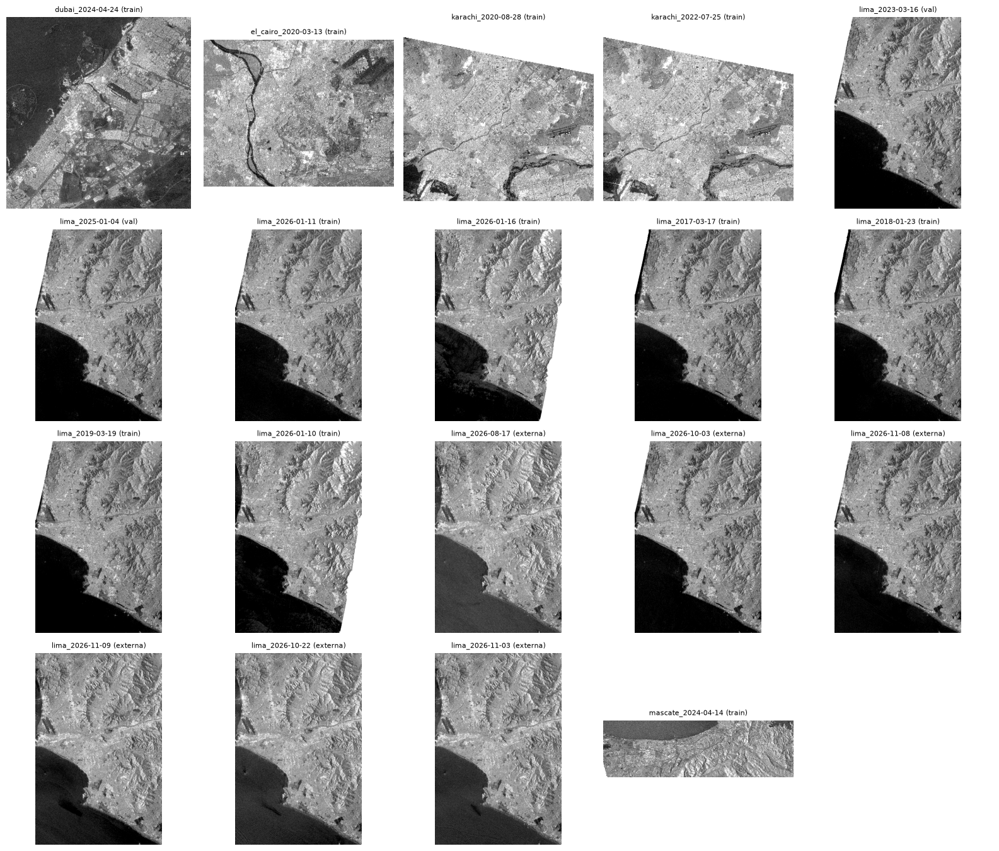

In [5]:
def leer(clave, carpeta="escenas"):
    with rasterio.open(f"Data/procesado/{carpeta}/{clave}.tif") as f:
        vh, vv, sombra = f.read().astype("float32")
        perfil = f.profile
    valido = (vv > 0) & (vh > 0)
    vv[~valido], vh[~valido] = np.nan, np.nan
    return 10 * np.log10(vv), 10 * np.log10(vh), valido, (sombra > 0) & valido, perfil


def etiqueta(clave):
    with rasterio.open(f"Data/procesado/etiquetas/{clave}.tif") as f:
        return f.read(1)


fig, ejes = plt.subplots(int(np.ceil(len(escenas) / 5)), 5, figsize=(16, 3.4 * np.ceil(len(escenas) / 5)))
for ax, e in zip(ejes.flat, escenas.itertuples()):
    ax.imshow(leer(e.clave)[0][::8, ::8], cmap="gray", vmin=-25, vmax=5)
    ax.set_title(f"{e.clave} ({e.rol})", fontsize=8)
for ax in ejes.flat:
    ax.axis("off")
plt.tight_layout()

### 2.3 Pendiente y cobertura del suelo

Se leen en línea de Planetary Computer y se llevan a la grilla de cada escena:

* **Pendiente** (DEM Copernicus 30 m): el agua de lluvia se acumula en terreno plano; en las laderas lo oscuro es sombra.
* **ESA WorldCover 2021**: mapa de cobertura (agua permanente = clase 80). Solo se usa para validar los datos.

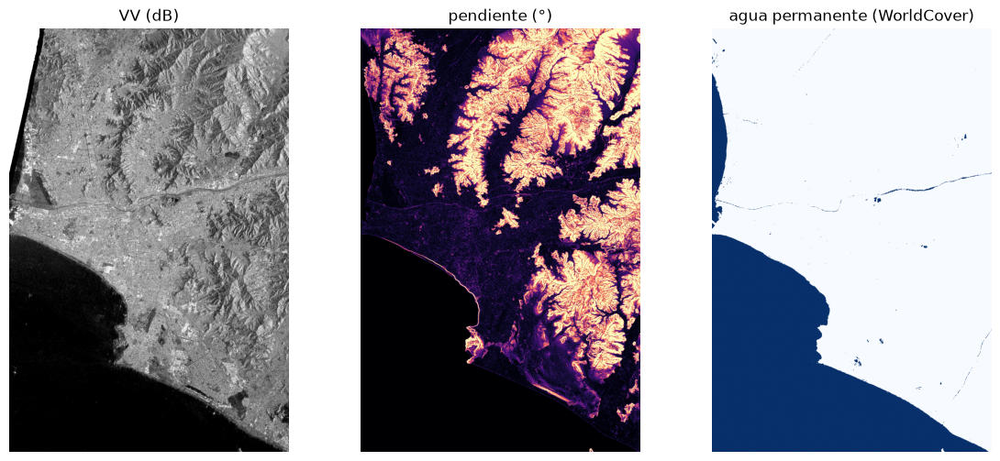

In [6]:
import requests
from functools import lru_cache
from rasterio.merge import merge
from rasterio.warp import reproject, Resampling
from scipy import ndimage


@lru_cache
def mosaico(coleccion, ciudad):
    x0, y0, x1, y1 = cajas[ciudad]
    caja = [x0 - 0.02, y0 - 0.02, x1 + 0.02, y1 + 0.02]
    items = requests.post("https://planetarycomputer.microsoft.com/api/stac/v1/search",
                          json={"collections": [coleccion], "bbox": caja,
                                "datetime": "2021-01-01T00:00:00Z/2021-12-31T23:59:59Z"}).json()["features"]
    token = requests.get(f"https://planetarycomputer.microsoft.com/api/sas/v1/token/{coleccion}").json()["token"]
    capa = "map" if coleccion == "esa-worldcover" else "data"
    arr, transform = merge([rasterio.open(it["assets"][capa]["href"] + "?" + token) for it in items], bounds=caja)
    return arr[0], transform


def en_grilla(coleccion, ciudad, perfil, metodo):
    arr, transform = mosaico(coleccion, ciudad)
    out = np.zeros((perfil["height"], perfil["width"]), arr.dtype)
    reproject(arr, out, src_transform=transform, src_crs="EPSG:4326", dst_transform=perfil["transform"],
              dst_crs=perfil["crs"], resampling=metodo)
    return out


def pendiente(ciudad, perfil):
    dem = ndimage.uniform_filter(en_grilla("cop-dem-glo-30", ciudad, perfil, Resampling.bilinear), 3)
    dy, dx = np.gradient(dem, 10)
    return np.degrees(np.arctan(np.hypot(dx, dy)))


vv, vh, valido, sombra, perfil = leer("lima_2017-03-17")
fig, ejes = plt.subplots(1, 3, figsize=(14, 6))
ejes[0].imshow(vv[::4, ::4], cmap="gray", vmin=-25, vmax=5)
ejes[0].set_title("VV (dB)")
ejes[1].imshow(pendiente("lima", perfil)[::4, ::4], cmap="magma", vmin=0, vmax=30)
ejes[1].set_title("pendiente (°)")
ejes[2].imshow(en_grilla("esa-worldcover", "lima", perfil, Resampling.nearest)[::4, ::4] == 80, cmap="Blues")
ejes[2].set_title("agua permanente (WorldCover)")
for ax in ejes:
    ax.axis("off")

### 2.4 Etiqueta: máscara de agua del mismo día

El día de la lluvia la ciudad está nublada y no hay imagen óptica, así que la etiqueta sale del propio radar:

1. Umbral de **Otsu** en VV y en VH (como máximo −15 y −22 dB). Agua = VV **y** VH por debajo del umbral.
2. Fuera de la sombra de radar y solo en terreno plano (pendiente < 5°).
3. Se borran las manchas de menos de 10 píxeles (0.1 ha).

Se guarda en `Data/procesado/etiquetas/`: 1 agua, 0 no agua, 255 sin dato.

In [7]:
def otsu(x):
    conteo, bordes = np.histogram(np.clip(x, -30, 5), bins=256, range=(-30, 5))
    centro = (bordes[:-1] + bordes[1:]) / 2
    w = np.cumsum(conteo) / conteo.sum()
    mu = np.cumsum(conteo * centro) / conteo.sum()
    return centro[np.argmax((mu[-1] * w - mu) ** 2 / (w * (1 - w) + 1e-12))]


Path("Data/procesado/etiquetas").mkdir(exist_ok=True)
umbrales = []
for e in escenas.itertuples():
    vv, vh, valido, sombra, perfil = leer(e.clave)
    muestra = np.random.default_rng(0).choice(np.flatnonzero(valido), 2_000_000)
    t_vv = min(otsu(vv.flat[muestra]), -15)
    t_vh = min(otsu(vh.flat[muestra]), -22)
    agua = (vv < t_vv) & (vh < t_vh) & ~sombra & (pendiente(e.ciudad, perfil) < 5)
    agua = ndimage.binary_opening(agua)
    manchas, _ = ndimage.label(agua)
    agua &= np.bincount(manchas.ravel())[manchas] >= 10
    perfil.update(count=1, dtype="uint8", nodata=255, compress="deflate")
    with rasterio.open(f"Data/procesado/etiquetas/{e.clave}.tif", "w", **perfil) as f:
        f.write(np.where(valido & ~sombra, agua, 255).astype("uint8"), 1)
    umbrales.append({"clave": e.clave, "umbral_vv": t_vv, "umbral_vh": t_vh, "agua_%": 100 * agua[valido].mean()})
pd.DataFrame(umbrales).round(2)

,clave,umbral_vv,umbral_vh,agua_%
0,dubai_2024-04-24,-15.00,-22,36.74
1,el_cairo_2020-03-13,-15.00,-22,5.67
2,karachi_2020-08-28,-15.00,-22,3.92
3,karachi_2022-07-25,-15.00,-22,3.06
4,lima_2023-03-16,-17.22,-22,26.02
5,lima_2025-01-04,-17.22,-22,26.00
6,lima_2026-01-11,-16.26,-22,26.22
7,lima_2026-01-16,-15.85,-22,26.66
8,lima_2017-03-17,-17.08,-22,26.37
9,lima_2018-01-23,-16.94,-22,26.47


### 2.5 ¿Sirve cada escena para segmentar agua?

Se compara cada escena con el agua permanente de WorldCover, una referencia independiente:

| Criterio | Qué mide | Umbral |
|---|---|---|
| cobertura | fracción de la ciudad con dato | ≥ 0.80 |
| AUC VV o VH | qué tan bien separa el radar el agua de la tierra (1 perfecto, 0.5 azar) | ≥ 0.90 |
| recall de la máscara | agua permanente que la máscara marca | ≥ 0.80 |
| falsa agua | tierra seca que la máscara marca como agua | ≤ 0.03 |

Solo las escenas que cumplen todo se usan en los modelos.

In [8]:
from scipy.stats import mannwhitneyu

filas = []
for e in escenas.itertuples():
    vv, vh, valido, sombra, perfil = leer(e.clave)
    et = etiqueta(e.clave)
    wc = en_grilla("esa-worldcover", e.ciudad, perfil, Resampling.nearest)
    agua = np.flatnonzero((et != 255) & (wc == 80))
    tierra = np.flatnonzero((et != 255) & np.isin(wc, [10, 20, 30, 40, 50, 60, 70, 100]))
    a = np.random.default_rng(0).choice(agua, 100_000)
    t = np.random.default_rng(1).choice(tierra, 100_000)
    filas.append({"clave": e.clave, "ciudad": e.ciudad, "rol": e.rol, "cobertura": valido.mean(),
                  "auc_vv": mannwhitneyu(vv.flat[t], vv.flat[a]).statistic / 1e10,
                  "auc_vh": mannwhitneyu(vh.flat[t], vh.flat[a]).statistic / 1e10,
                  "recall_mascara": (et.flat[agua] == 1).mean(),
                  "falsa_agua": (et.flat[tierra] == 1).mean()})
datos = pd.DataFrame(filas)
datos["sirve"] = ((datos.cobertura >= 0.8) & (datos[["auc_vv", "auc_vh"]].max(axis=1) >= 0.9)
                  & (datos.recall_mascara >= 0.8) & (datos.falsa_agua <= 0.03))
datos.to_csv("Data/procesado/validacion_datos.csv", index=False)
datos.round(3)

,clave,ciudad,rol,cobertura,auc_vv,auc_vh,recall_mascara,falsa_agua,sirve
0,dubai_2024-04-24,dubai,train,1.000,0.911,0.930,0.908,0.146,False
1,el_cairo_2020-03-13,el_cairo,train,1.000,0.933,0.917,0.713,0.039,False
2,karachi_2020-08-28,karachi,train,0.826,0.960,0.967,0.763,0.014,False
3,karachi_2022-07-25,karachi,train,0.826,0.947,0.961,0.603,0.010,False
4,lima_2023-03-16,lima,val,0.969,0.995,0.990,0.976,0.008,True
5,lima_2025-01-04,lima,val,0.971,0.994,0.989,0.973,0.008,True
6,lima_2026-01-11,lima,train,0.972,0.994,0.990,0.976,0.010,True
7,lima_2026-01-16,lima,train,0.944,0.991,0.988,0.952,0.008,True
8,lima_2017-03-17,lima,train,0.981,0.990,0.985,0.979,0.010,True
9,lima_2018-01-23,lima,train,0.982,0.989,0.984,0.979,0.010,True


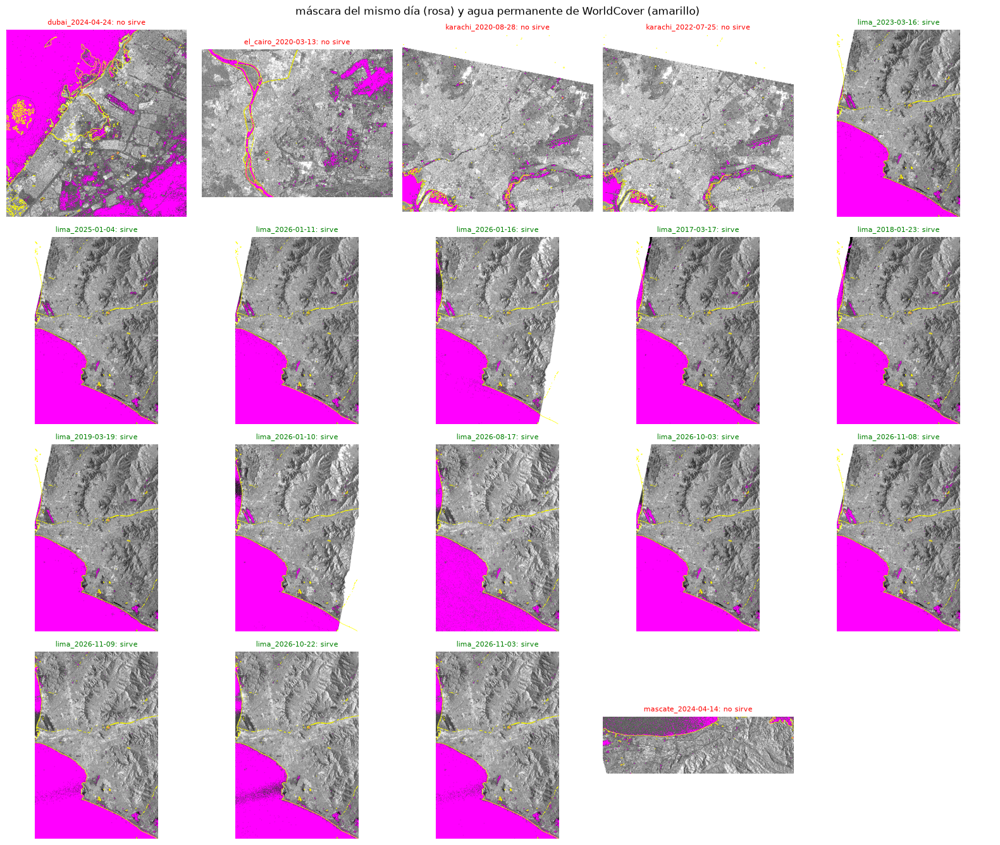

In [9]:
fig, ejes = plt.subplots(int(np.ceil(len(datos) / 5)), 5, figsize=(16, 3.4 * np.ceil(len(datos) / 5)))
for ax, e in zip(ejes.flat, datos.itertuples()):
    vv, vh, valido, sombra, perfil = leer(e.clave)
    et = etiqueta(e.clave)[::8, ::8]
    ax.imshow(vv[::8, ::8], cmap="gray", vmin=-25, vmax=5)
    ax.imshow(np.ma.masked_where(et != 1, et), cmap="cool", vmin=0, vmax=1)
    ax.contour(en_grilla("esa-worldcover", e.ciudad, perfil, Resampling.nearest)[::8, ::8] == 80, [0.5],
               colors="yellow", linewidths=0.5)
    ax.set_title(f"{e.clave}: {'sirve' if e.sirve else 'no sirve'}", fontsize=8, color="green" if e.sirve else "red")
for ax in ejes.flat:
    ax.axis("off")
plt.suptitle("máscara del mismo día (rosa) y agua permanente de WorldCover (amarillo)")
plt.tight_layout()

**Resultado.** Las 14 escenas de Lima sirven: el radar separa el agua de la tierra (AUC 0.97 a 0.995) y la máscara del
mismo día marca el 92-98 % del agua permanente con solo 0.6-1.4 % de falsa agua. Las otras ciudades no sirven:

* **Dubái y El Cairo**: la arena del desierto sale casi tan oscura como el agua; la máscara marca como agua el 14.6 % y el
  3.9 % de la tierra seca.
* **Karachi y Mascate**: el mar agitado por el viento no sale oscuro en VV; la máscara recupera solo el 23-76 % del agua
  permanente.

Por eso los modelos se entrenan y validan solo con escenas de Lima.

### 2.6 Parches

Las escenas de train y validación que sirven se cortan en parches de 256 × 256 píxeles (2.56 km) con al menos la mitad de
píxeles con dato. `X` = imagen (VV, VH en dB), `Y` = etiqueta, `M` = píxeles evaluables.

In [10]:
usar = datos[datos.sirve & datos.rol.isin(["train", "val"])]
X, Y, M, info = [], [], [], []
for e in usar.itertuples():
    vv, vh, valido, sombra, perfil = leer(e.clave)
    et = etiqueta(e.clave)
    for i in range(0, et.shape[0] - 255, 256):
        for j in range(0, et.shape[1] - 255, 256):
            p = et[i:i + 256, j:j + 256]
            if (p != 255).mean() < 0.5:
                continue
            X.append(np.stack([vv[i:i + 256, j:j + 256], vh[i:i + 256, j:j + 256]]).astype("float16"))
            Y.append(p == 1)
            M.append(p != 255)
            info.append({"clave": e.clave, "rol": e.rol, "agua": (p == 1).mean(), "con_dato": (p != 255).mean()})
X, Y, M, info = np.array(X), np.array(Y), np.array(M), pd.DataFrame(info)
tr, va = (info.rol == "train").to_numpy(), (info.rol == "val").to_numpy()
info.groupby(["rol", "clave"]).agg(parches=("agua", "size"), agua_media=("agua", "mean")).round(3)

parches  agua_media
rol   clave                               
train lima_2017-03-17      224       0.259
      lima_2018-01-23      224       0.260
      lima_2019-03-19      221       0.256
      lima_2026-01-10      223       0.261
      lima_2026-01-11      221       0.259
      lima_2026-01-16      223       0.258
val   lima_2023-03-16      221       0.257
      lima_2025-01-04      221       0.257

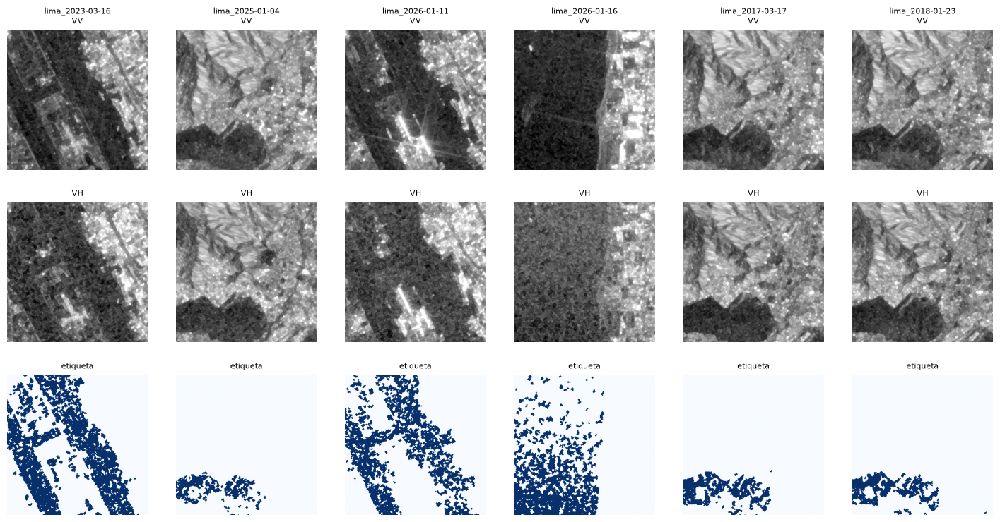

In [11]:
ejemplos = info[info.agua.between(0.05, 0.5) & (info.con_dato == 1)].groupby("clave").head(1).index[:6]
fig, ejes = plt.subplots(3, len(ejemplos), figsize=(3 * len(ejemplos), 9), squeeze=False)
for c, k in enumerate(ejemplos):
    ejes[0, c].imshow(X[k, 0].astype("float32"), cmap="gray", vmin=-25, vmax=5)
    ejes[0, c].set_title(f"{info.clave[k]}\nVV", fontsize=8)
    ejes[1, c].imshow(X[k, 1].astype("float32"), cmap="gray", vmin=-30, vmax=-5)
    ejes[1, c].set_title("VH", fontsize=8)
    ejes[2, c].imshow(np.where(M[k], Y[k], np.nan), cmap="Blues", vmin=0, vmax=1)
    ejes[2, c].set_title("etiqueta", fontsize=8)
for ax in ejes.flat:
    ax.axis("off")

## 3. Normalización

Cada canal se recorta a [−30, 5] dB y se estandariza con la media y la desviación de los parches de **train** (sin mirar
validación ni la aplicación externa). Los píxeles sin dato quedan en 0, que equivale a la media.

In [12]:
entrenamiento = np.clip(X[tr].astype("float32"), -30, 5)
media = np.nanmean(entrenamiento, axis=(0, 2, 3))
desv = np.nanstd(entrenamiento, axis=(0, 2, 3))
del entrenamiento


def normalizar(x):
    return np.nan_to_num((np.clip(x.astype("float32"), -30, 5) - media[:, None, None]) / desv[:, None, None])


muestra = normalizar(X[tr][:200])
pd.DataFrame({"media dB": media, "desviación dB": desv,
              "media normalizada": muestra.mean(axis=(0, 2, 3)), "desviación normalizada": muestra.std(axis=(0, 2, 3))},
             index=["VV", "VH"]).round(3)

,media dB,desviación dB,media normalizada,desviación normalizada
VV,-13.014000,9.070,0.143,0.878
VH,-19.094999,7.032,0.186,0.920


## 4. Modelo: U-Net

La **U-Net** resume la imagen en mapas cada vez más pequeños (codificador) y luego recupera la resolución (decodificador) con
conexiones de salto, para dar una probabilidad de agua por píxel. Se prueban tres codificadores preentrenados en ImageNet:
ResNet34, EfficientNet-B0 y MobileNetV2.

* Pérdida: entropía cruzada binaria + Dice, solo en píxeles evaluables.
* AdamW (lr 1e-4), lotes de 16, giros de 90° al azar.
* Hasta 30 épocas; se para si el IoU de validación no mejora en 5. Se guarda la época con mejor IoU.
* El umbral de decisión se elige en validación.

In [13]:
import torch, segmentation_models_pytorch as smp

gpu = "cuda" if torch.cuda.is_available() else "cpu"
Xtr = torch.tensor(normalizar(X[tr]), dtype=torch.float16, device=gpu)
Ytr = torch.tensor(Y[tr][:, None], device=gpu)
Mtr = torch.tensor(M[tr][:, None], device=gpu)
Xva = torch.tensor(normalizar(X[va]), dtype=torch.float16, device=gpu)
Yva = torch.tensor(Y[va][:, None], device=gpu)
Mva = torch.tensor(M[va][:, None], device=gpu)


def perdida(logits, y, m):
    y, m = y.float(), m.float()
    bce = (torch.nn.functional.binary_cross_entropy_with_logits(logits, y, reduction="none") * m).sum() / m.sum()
    p = torch.sigmoid(logits) * m
    return bce + 1 - (2 * (p * y).sum() + 1) / (p.sum() + (y * m).sum() + 1)


def predecir(modelo, x):
    modelo.eval()
    with torch.no_grad(), torch.autocast(gpu, dtype=torch.bfloat16):
        return torch.cat([torch.sigmoid(modelo(x[i:i + 32].float())).float() for i in range(0, len(x), 32)])


def metricas(p, y, m, umbral):
    a = p >= umbral
    tp, fp, fn = (a & y & m).sum().item(), (a & ~y & m).sum().item(), (~a & y & m).sum().item()
    return {"IoU": tp / max(tp + fp + fn, 1), "F1": 2 * tp / max(2 * tp + fp + fn, 1),
            "Precision": tp / max(tp + fp, 1), "Recall": tp / max(tp + fn, 1)}


print(gpu, "· train", tuple(Xtr.shape), "· val", tuple(Xva.shape))

cuda · train (1336, 2, 256, 256) · val (442, 2, 256, 256)


In [14]:
Path("Data/procesado/dl").mkdir(exist_ok=True)
historial, resultados = [], []
for encoder in ["resnet34", "efficientnet-b0", "mobilenet_v2"]:
    torch.manual_seed(0)
    np.random.seed(0)
    modelo = smp.Unet(encoder, encoder_weights="imagenet", in_channels=2, classes=1).to(gpu)
    optimizador = torch.optim.AdamW(modelo.parameters(), lr=1e-4)
    mejor_iou, sin_mejora = 0, 0
    for epoca in range(1, 31):
        modelo.train()
        perdidas = []
        for lote in torch.randperm(len(Xtr), device=gpu).split(16):
            k = np.random.randint(4)
            x, y, m = [t[lote].rot90(k, [2, 3]) for t in (Xtr, Ytr, Mtr)]
            with torch.autocast(gpu, dtype=torch.bfloat16):
                logits = modelo(x.float())
            loss = perdida(logits.float(), y, m)
            optimizador.zero_grad()
            loss.backward()
            optimizador.step()
            perdidas.append(loss.item())
        p = predecir(modelo, Xva)
        iou = metricas(p, Yva, Mva, 0.5)["IoU"]
        historial.append({"encoder": encoder, "epoca": epoca, "perdida_train": np.mean(perdidas),
                          "perdida_val": perdida(torch.logit(p.clamp(1e-6, 1 - 1e-6)), Yva, Mva).item(), "iou_val": iou})
        print(f"{encoder} · época {epoca} · pérdida train {np.mean(perdidas):.3f} · IoU val {iou:.3f}")
        if iou > mejor_iou:
            mejor_iou, mejor_epoca, sin_mejora = iou, epoca, 0
            pesos = {k: v.clone() for k, v in modelo.state_dict().items()}
        else:
            sin_mejora += 1
            if sin_mejora == 5:
                break
    modelo.load_state_dict(pesos)
    p = predecir(modelo, Xva)
    umbral = max(np.arange(0.1, 0.95, 0.05).round(2), key=lambda u: metricas(p, Yva, Mva, u)["IoU"])
    torch.save({"pesos": pesos, "encoder": encoder, "media": media.tolist(), "desv": desv.tolist(), "umbral": float(umbral)},
               f"Data/procesado/dl/unet_{encoder}.pt")
    resultados.append({"encoder": encoder, "mejor_epoca": mejor_epoca, "umbral": umbral, **metricas(p, Yva, Mva, umbral)})

resnet34 · época 1 · pérdida train 0.960 · IoU val 0.956


resnet34 · época 2 · pérdida train 0.577 · IoU val 0.944


resnet34 · época 3 · pérdida train 0.448 · IoU val 0.969


resnet34 · época 4 · pérdida train 0.346 · IoU val 0.973


resnet34 · época 5 · pérdida train 0.305 · IoU val 0.974


resnet34 · época 6 · pérdida train 0.245 · IoU val 0.975


... (58 outputs left out)

mobilenet_v2 · época 24 · pérdida train 0.052 · IoU val 0.982


mobilenet_v2 · época 25 · pérdida train 0.068 · IoU val 0.979


mobilenet_v2 · época 26 · pérdida train 0.045 · IoU val 0.980


mobilenet_v2 · época 27 · pérdida train 0.063 · IoU val 0.983


## 5. Resultados en validación

**IoU** = intersección / unión del agua predicha y la etiqueta; **F1** = media armónica de precisión y recall. Todo se mide
sobre los píxeles evaluables de las escenas de validación.

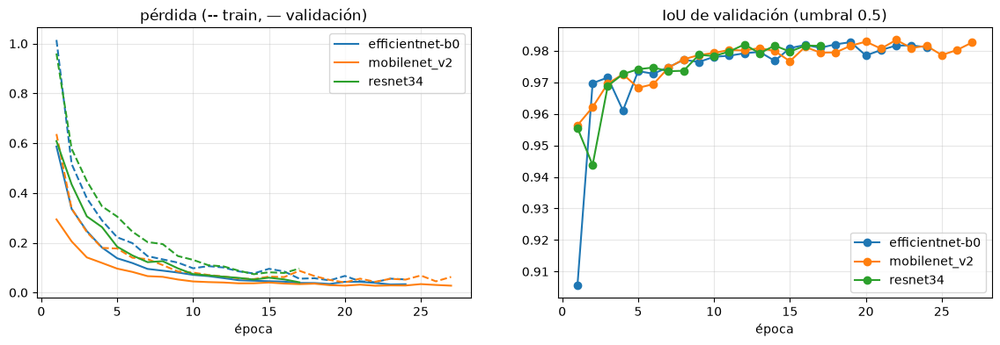

In [15]:
historial = pd.DataFrame(historial)
historial.to_csv("Data/procesado/dl/historial.csv", index=False)
fig, ejes = plt.subplots(1, 2, figsize=(14, 4))
for encoder, h in historial.groupby("encoder"):
    linea, = ejes[0].plot(h.epoca, h.perdida_train, "--")
    ejes[0].plot(h.epoca, h.perdida_val, color=linea.get_color(), label=encoder)
    ejes[1].plot(h.epoca, h.iou_val, "o-", label=encoder)
ejes[0].set_title("pérdida (-- train, — validación)")
ejes[1].set_title("IoU de validación (umbral 0.5)")
for ax in ejes:
    ax.set_xlabel("época")
    ax.grid(alpha=0.3)
    ax.legend()

In [16]:
resultados = pd.DataFrame(resultados).sort_values("IoU", ascending=False)
resultados.to_csv("Data/procesado/dl/resultados_validacion.csv", index=False)
mejor = resultados.encoder.iloc[0]
print("mejor encoder:", mejor)
resultados.round(3)

mejor encoder: efficientnet-b0


,encoder,mejor_epoca,umbral,IoU,F1,Precision,Recall
1,efficientnet-b0,19,0.65,0.984,0.992,0.991,0.992
2,mobilenet_v2,22,0.45,0.983,0.992,0.991,0.992
0,resnet34,12,0.55,0.982,0.991,0.991,0.991


In [17]:
guardado = torch.load(f"Data/procesado/dl/unet_{mejor}.pt")
modelo = smp.Unet(mejor, encoder_weights=None, in_channels=2, classes=1).to(gpu)
modelo.load_state_dict(guardado["pesos"])
umbral = guardado["umbral"]
p = predecir(modelo, Xva)
info_va = info[va].reset_index(drop=True)
pd.DataFrame([{"clave": c, "parches": len(g), **metricas(p[g.index.to_numpy()], Yva[g.index.to_numpy()],
                                                          Mva[g.index.to_numpy()], umbral)}
              for c, g in info_va.groupby("clave")]).round(3)

,clave,parches,IoU,F1,Precision,Recall
0,lima_2023-03-16,221,0.985,0.992,0.992,0.992
1,lima_2025-01-04,221,0.983,0.991,0.990,0.992


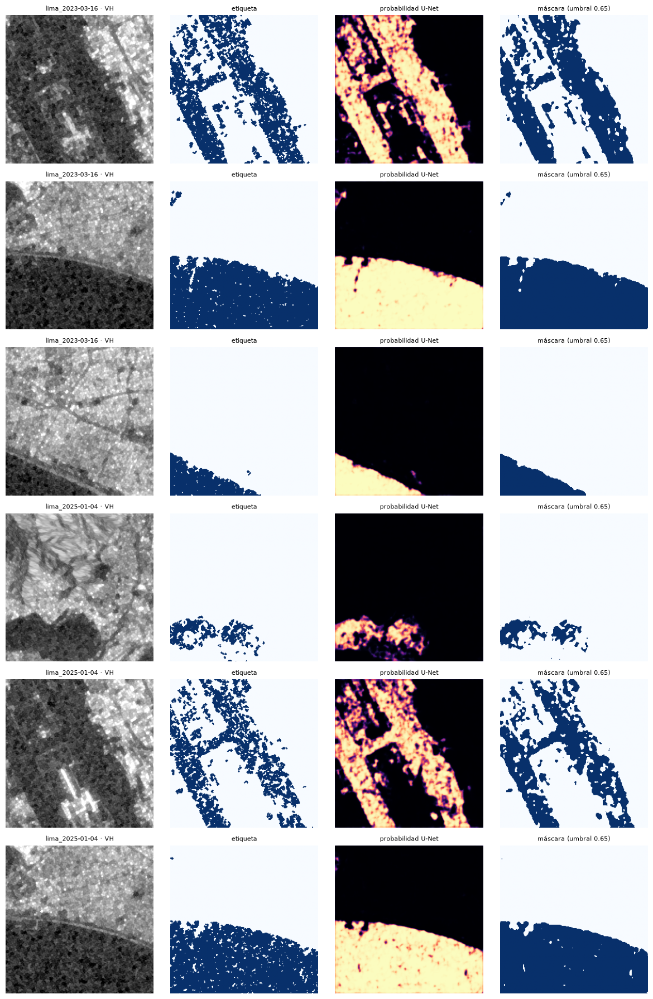

In [18]:
ejemplos = info_va[info_va.agua.between(0.05, 0.5) & (info_va.con_dato == 1)].groupby("clave").head(3).index[:6]
fig, ejes = plt.subplots(len(ejemplos), 4, figsize=(12, 3 * len(ejemplos)), squeeze=False)
for fila, k in zip(ejes, ejemplos):
    fila[0].imshow(X[va][k, 1].astype("float32"), cmap="gray", vmin=-30, vmax=-5)
    fila[0].set_title(f"{info_va.clave[k]} · VH", fontsize=8)
    fila[1].imshow(Yva[k, 0].cpu(), cmap="Blues")
    fila[1].set_title("etiqueta", fontsize=8)
    fila[2].imshow(p[k, 0].cpu(), cmap="magma", vmin=0, vmax=1)
    fila[2].set_title("probabilidad U-Net", fontsize=8)
    fila[3].imshow((p[k, 0] >= umbral).cpu(), cmap="Blues")
    fila[3].set_title(f"máscara (umbral {umbral})", fontsize=8)
for ax in ejes.flat:
    ax.axis("off")
plt.tight_layout()

## 6. Aplicación externa: lluvias de Lima 2026

Cada escena completa se predice con una ventana deslizante (256 px, paso 128, promedio en los solapes). Se compara con la
máscara del mismo día y se guarda la probabilidad como GeoTIFF en `Data/procesado/dl/predicciones/` (×100, 255 = sin dato).

In [19]:
def mapa(modelo, vv, vh):
    modelo.eval()
    x = normalizar(np.stack([vv, vh]))
    alto, ancho = vv.shape
    suma, veces = np.zeros((alto, ancho), "float32"), np.zeros((alto, ancho), "float32")
    filas = list(range(0, alto - 256, 128)) + [alto - 256]
    columnas = list(range(0, ancho - 256, 128)) + [ancho - 256]
    with torch.no_grad(), torch.autocast(gpu, dtype=torch.bfloat16):
        for i in filas:
            lote = torch.tensor(np.stack([x[:, i:i + 256, j:j + 256] for j in columnas]), dtype=torch.float32, device=gpu)
            prob = torch.sigmoid(modelo(lote)).float().cpu().numpy()[:, 0]
            for j, pj in zip(columnas, prob):
                suma[i:i + 256, j:j + 256] += pj
                veces[i:i + 256, j:j + 256] += 1
    return suma / veces


Path("Data/procesado/dl/predicciones").mkdir(exist_ok=True)
lima = datos[datos.sirve & datos.clave.str.startswith("lima")]
probabilidad, externa = {}, []
for e in lima.itertuples():
    vv, vh, valido, sombra, perfil = leer(e.clave)
    p = np.where(valido, mapa(modelo, vv, vh), np.nan)
    probabilidad[e.clave] = (p, perfil.copy())
    if e.rol == "externa":
        et = etiqueta(e.clave)
        externa.append({"clave": e.clave, **metricas(p, et == 1, et != 255, umbral)})
        perfil.update(count=1, dtype="uint8", nodata=255, compress="deflate")
        with rasterio.open(f"Data/procesado/dl/predicciones/{e.clave}.tif", "w", **perfil) as f:
            f.write(np.where(valido, np.round(np.nan_to_num(p) * 100), 255).astype("uint8"), 1)
externa = pd.DataFrame(externa)
externa.to_csv("Data/procesado/dl/resultados_externa.csv", index=False)
externa.round(3)

,clave,IoU,F1,Precision,Recall
0,lima_2026-08-17,0.926,0.962,0.967,0.957
1,lima_2026-10-03,0.978,0.989,0.995,0.983
2,lima_2026-11-08,0.971,0.986,0.995,0.976
3,lima_2026-11-09,0.958,0.979,0.994,0.964
4,lima_2026-10-22,0.922,0.959,0.991,0.930
5,lima_2026-11-03,0.946,0.972,0.992,0.953


### 6.1 Agua nueva en cada lluvia

Todas las fechas de Lima se llevan a la misma grilla. **Agua permanente** = lo que el modelo marca como agua en al menos el
80 % de las fechas (mar, río, lagunas). **Agua nueva** = agua de una fecha que está a más de 100 m del agua permanente (la
orilla se mueve con las olas y la marea) y donde todas las fechas tienen dato. Abajo, el baipás Nueva Esperanza (Villa María
del Triunfo), que se inunda con las lluvias.

In [20]:
from rasterio.transform import rowcol
from rasterio.warp import transform

ref = next(iter(probabilidad.values()))[1]


def alinear(p, perfil):
    out = np.full((ref["height"], ref["width"]), np.nan, "float32")
    reproject(p, out, src_transform=perfil["transform"], src_crs=perfil["crs"], dst_transform=ref["transform"],
              dst_crs=ref["crs"], resampling=Resampling.nearest, src_nodata=np.nan, dst_nodata=np.nan)
    return out


alineados = {c: alinear(*v) for c, v in probabilidad.items()}
es_agua = np.stack([a >= umbral for a in alineados.values()]).sum(0)
con_dato = np.stack([~np.isnan(a) for a in alineados.values()]).sum(0)
permanente = (es_agua >= 0.8 * con_dato) & (con_dato >= 3)
lejos = ~ndimage.binary_dilation(permanente, iterations=10) & (con_dato == len(alineados))
nueva = pd.DataFrame([{"clave": c, "rol": escenas.set_index("clave").rol[c], "agua_km2": (a >= umbral).sum() / 1e4,
                       "agua_nueva_km2": ((a >= umbral) & lejos).sum() / 1e4} for c, a in alineados.items()])
nueva.to_csv("Data/procesado/dl/agua_nueva_lima.csv", index=False)
nueva.round(2)

,clave,rol,agua_km2,agua_nueva_km2
0,lima_2023-03-16,val,417.15,7.94
1,lima_2025-01-04,val,417.15,7.59
2,lima_2026-01-11,train,418.48,7.85
3,lima_2026-01-16,train,412.84,6.12
4,lima_2017-03-17,train,424.74,6.59
5,lima_2018-01-23,train,426.23,6.79
6,lima_2019-03-19,train,417.74,7.08
7,lima_2026-01-10,train,415.70,6.53
8,lima_2026-08-17,externa,409.75,1.94
9,lima_2026-10-03,externa,423.36,10.26


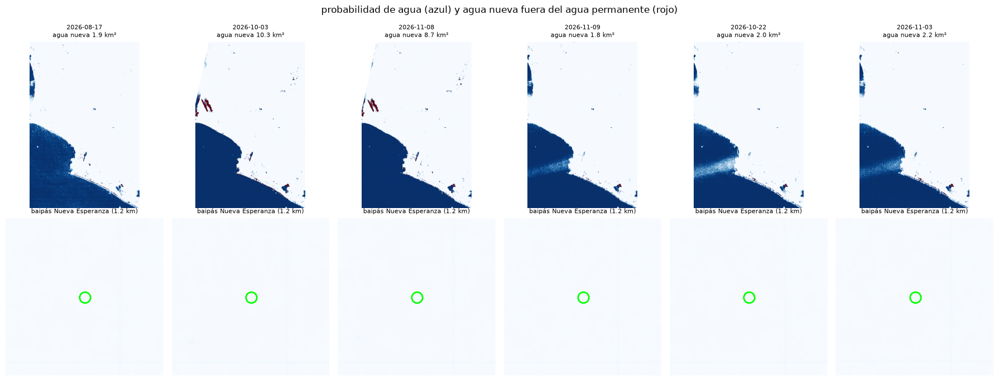

In [21]:
x, y = transform("EPSG:4326", ref["crs"], [-76.9435], [-12.1804])
fila, col = rowcol(ref["transform"], x[0], y[0])
fechas = [c for c in alineados if escenas.set_index("clave").rol[c] == "externa"]
fig, ejes = plt.subplots(2, len(fechas), figsize=(3 * len(fechas), 7), squeeze=False)
for c, clave in enumerate(fechas):
    a = alineados[clave]
    ejes[0, c].imshow(a[::6, ::6], cmap="Blues", vmin=0, vmax=1)
    ejes[0, c].imshow(np.where((a >= umbral) & lejos, 1.0, np.nan)[::6, ::6], cmap="Reds", vmin=0, vmax=1)
    ejes[0, c].set_title(f"{clave[5:]}\nagua nueva {nueva.set_index('clave').agua_nueva_km2[clave]:.1f} km²", fontsize=8)
    ejes[1, c].imshow(a[fila - 60:fila + 60, col - 60:col + 60], cmap="Blues", vmin=0, vmax=1)
    ejes[1, c].imshow(np.where((a >= umbral) & lejos, 1.0, np.nan)[fila - 60:fila + 60, col - 60:col + 60], cmap="Reds", vmin=0, vmax=1)
    ejes[1, c].plot(60, 60, "o", mfc="none", mec="lime", ms=14, mew=2)
    ejes[1, c].set_title("baipás Nueva Esperanza (1.2 km)", fontsize=8)
for ax in ejes.flat:
    ax.axis("off")
plt.suptitle("probabilidad de agua (azul) y agua nueva fuera del agua permanente (rojo)")
plt.tight_layout()

### 6.2 ¿El agua nueva es de la lluvia? Comparación con días secos

Las pistas, la arena y la orilla del mar también salen oscuras en días sin lluvia. Se predice con la U-Net cada día seco y
cada lluvia se compara solo con los días secos de su mismo pase (el ángulo de vista cambia entre mañana y tarde) y de su
época. **Agua de lluvia** = agua ese día que en los días secos casi nunca es agua (≤ 20 %) y donde VV bajó más de 3 dB
respecto de la mediana seca. Para saber cuánto marca este criterio sin lluvia, se aplica también a cada día seco contra
los otros.

In [22]:
import warnings
warnings.filterwarnings("ignore", message="All-NaN slice")
pase_de = dict(zip(escenas.clave, escenas.safe.map(pase))) | dict(zip(secas.clave, secas.pase))
rol_de = dict(zip(escenas.clave, escenas.rol))
refs = lambda c: secas.clave[(secas.pase == pase_de[c]) & (secas.epoca == epoca_de(c)) & (secas.clave != c)]
vv_al, agua_al = {}, {}
for s in secas.itertuples():
    vv, vh, valido, sombra, perfil = leer(s.clave, "referencia")
    vv_al[s.clave] = alinear(vv, perfil)
    agua_al[s.clave] = alinear(np.where(valido, mapa(modelo, vv, vh), np.nan), perfil) >= umbral
for c, (p, perfil) in probabilidad.items():
    vv_al[c] = alinear(leer(c)[0], perfil)
    agua_al[c] = alineados[c] >= umbral


def agua_de_lluvia(clave, refs):
    vv_seco = np.nanmedian(np.stack([vv_al[r] for r in refs]), 0)
    agua_seco = np.mean(np.stack([agua_al[r] for r in refs]), 0)
    return ndimage.binary_opening(agua_al[clave] & (agua_seco <= 0.2) & (vv_al[clave] - vv_seco < -3))


lluvia, filas = {}, []
for c in alineados:
    if pase_de[c] != "otra":
        lluvia[c] = agua_de_lluvia(c, refs(c))
        filas.append({"escena": c, "dia": "lluvia", "rol": rol_de[c], "pase": pase_de[c], "epoca": epoca_de(c),
                      "agua_nueva_km2": (agua_al[c] & lejos).sum() / 1e4, "agua_de_lluvia_km2": lluvia[c].sum() / 1e4})
for s in secas.itertuples():
    filas.append({"escena": s.clave, "dia": "seco", "rol": "referencia", "pase": s.pase, "epoca": s.epoca,
                  "agua_nueva_km2": (agua_al[s.clave] & lejos).sum() / 1e4,
                  "agua_de_lluvia_km2": agua_de_lluvia(s.clave, refs(s.clave)).sum() / 1e4})
comparacion = pd.DataFrame(filas)
comparacion.to_csv("Data/procesado/dl/agua_de_lluvia.csv", index=False)
comparacion.round(2)

,escena,dia,rol,pase,epoca,agua_nueva_km2,agua_de_lluvia_km2
0,lima_2023-03-16,lluvia,val,mañana,2026,7.94,0.87
1,lima_2025-01-04,lluvia,val,mañana,2026,7.59,0.50
2,lima_2026-01-11,lluvia,train,mañana,2026,7.85,0.41
3,lima_2017-03-17,lluvia,train,mañana,2017,6.59,0.40
4,lima_2018-01-23,lluvia,train,mañana,2017,6.79,0.73
5,lima_2019-03-19,lluvia,train,mañana,2017,7.08,0.82
6,lima_2026-08-17,lluvia,externa,tarde,2026,1.94,0.15
7,lima_2026-10-03,lluvia,externa,mañana,2026,10.26,0.63
8,lima_2026-11-08,lluvia,externa,mañana,2026,8.69,0.28
9,lima_2026-11-09,lluvia,externa,tarde,2026,1.81,0.29


                    agua_nueva_km2        agua_de_lluvia_km2      
                               min    max                min   max
epoca pase   dia                                                  
2017  mañana lluvia           6.59   7.08               0.40  0.82
             seco             5.43   6.09               0.08  0.50
2026  mañana lluvia           7.59  10.26               0.28  0.87
             seco             5.57   9.36               0.04  0.28
      tarde  lluvia           1.81   2.24               0.15  0.29
             seco             2.11   2.79               0.05  0.62


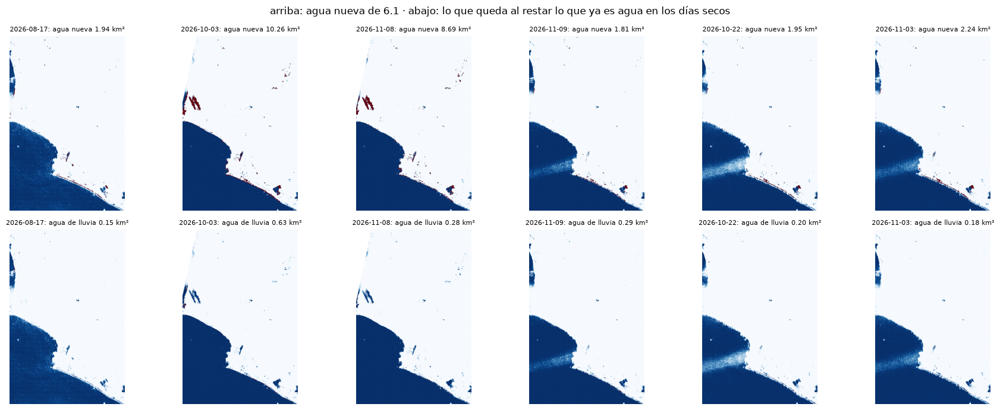

In [23]:
print(comparacion.groupby(["epoca", "pase", "dia"])[["agua_nueva_km2", "agua_de_lluvia_km2"]].agg(["min", "max"]).round(2))
fechas = [c for c in lluvia if rol_de[c] == "externa"]
fig, ejes = plt.subplots(2, len(fechas), figsize=(3 * len(fechas), 7), squeeze=False)
for j, c in enumerate(fechas):
    for i, (m, titulo) in enumerate([(agua_al[c] & lejos, "agua nueva"), (lluvia[c], "agua de lluvia")]):
        ejes[i, j].imshow(alineados[c][::6, ::6], cmap="Blues", vmin=0, vmax=1)
        ejes[i, j].imshow(np.where(ndimage.binary_dilation(m, iterations=3), 1.0, np.nan)[::6, ::6], cmap="Reds", vmin=0, vmax=1)
        ejes[i, j].set_title(f"{c[5:]}: {titulo} {m.sum() / 1e4:.2f} km²", fontsize=8)
for ax in ejes.flat:
    ax.axis("off")
plt.suptitle("arriba: agua nueva de 6.1 · abajo: lo que queda al restar lo que ya es agua en los días secos")
plt.tight_layout()

### 6.3 Validación con las noticias

Lugares que la prensa reportó inundados y la escena de Sentinel-1 más cercana: los aniegos de las lluvias de 2026 y, como
caso de control, el desborde del Huaycoloro y del Rímac en Huachipa, Campoy y Carapongo con el Niño costero de 2017 (agua
de río que cubrió calles y chacras durante horas; la pasada fue a las 05:38 del 17 de marzo). En un cuadrado del tamaño
del lugar se mide:

* cuánta agua marca la U-Net y cuánta queda como agua de lluvia (6.2);
* cuánto cambió VV respecto de la mediana de los días secos del mismo pase y época. El agua junto a paredes *sube* VV
  (doble rebote) en vez de bajarlo;
* el rango de ese cambio en los días secos (cada uno contra los otros);
* qué porcentaje de las zonas urbanas de Lima del mismo tamaño cambió menos ese día. Si el lugar inundado fuera
  detectable, estaría cerca del 0 % (bajó mucho) o del 100 % (subió mucho).

In [24]:
noticias = pd.DataFrame([
    ("Huaycoloro en la autopista Ramiro Prialé", -12.0203, -76.9524, 150, "lima_2017-03-17", "desborde sobre la autopista, 15-17 mar 2017 (RPP)"),
    ("Huachipa: Av. Las Torres con Ramiro Prialé", -12.0138, -76.9015, 200, "lima_2017-03-17", "Huachipa inundada desde la 1:00 del 17 mar (El Popular)"),
    ("Campoy: Malecón Checa", -12.0239, -76.9666, 200, "lima_2017-03-17", "Malecón Checa inundado el 17 mar (El Popular)"),
    ("Carapongo (ubicación aproximada)", -12.0029, -76.8643, 500, "lima_2017-03-17", "desborde del Rímac, tarde y noche del 16 mar (América TV)"),
    ("baipás Nueva Esperanza", -12.1804, -76.9435, 60, "lima_2026-08-17", "bus varado en el baipás (Andina, 17 ago)"),
    ("VES Sector 1 Grupo 1", -12.1874, -76.9471, 200, "lima_2026-08-17", "aguas servidas en 11 manzanas (Infobae, 16-18 ago)"),
    ("VMT José Gálvez", -12.2244, -76.9029, 300, "lima_2026-08-17", "viviendas inundadas (Caretas, 17 ago)"),
    ("baipás Nueva Esperanza", -12.1804, -76.9435, 60, "lima_2026-10-03", "inundado la madrugada del 2 oct (La República)"),
    ("baipás Nueva Esperanza", -12.1804, -76.9435, 60, "lima_2026-11-08", "inundado y cerrado el 5 nov (El Búho)"),
    ("VES Sector 1 Grupo 1", -12.1874, -76.9471, 200, "lima_2026-11-08", "desagüe colapsado, 4-5 nov (Caretas)"),
    ("SJM Av. Los Héroes", -12.1575, -76.9635, 150, "lima_2026-11-08", "aniegos el 4 nov (Caretas)"),
    ("Hospital de Emergencias VES", -12.2321, -76.9348, 100, "lima_2026-11-08", "aniego en el exterior, 5 nov (Andina)"),
    ("baipás Nueva Esperanza", -12.1804, -76.9435, 60, "lima_2026-11-09", "inundado de madrugada el 9 nov; Emape sacó el agua (RPP)"),
], columns=["lugar", "lat", "lon", "radio_m", "escena", "noticia"])
base = {c: np.nanmedian(np.stack([vv_al[r] for r in refs(c)]), 0) for c in set(noticias.escena) | set(secas.clave)}


def en_ventanas(dif, urbano, lado):
    ok = urbano & ~np.isnan(dif)
    suma = ndimage.uniform_filter(np.where(ok, dif, 0), lado)
    peso = ndimage.uniform_filter(ok.astype("float32"), lado)
    return np.where(peso > 0.6, suma / np.maximum(peso, 1e-6), np.nan)


cambio_en_ventanas = lambda clave, referencia, lado: en_ventanas(vv_al[clave] - referencia, referencia > -10, lado)


resultado = []
for n in noticias.itertuples():
    lado = 2 * int(n.radio_m / 10) + 1
    x, y = transform("EPSG:4326", ref["crs"], [n.lon], [n.lat])
    f, c = rowcol(ref["transform"], x[0], y[0])
    zona = np.s_[f - lado // 2:f + lado // 2 + 1, c - lado // 2:c + lado // 2 + 1]
    ventanas = cambio_en_ventanas(n.escena, base[n.escena], lado)
    ciudad = ventanas[::lado // 2 + 1, ::lado // 2 + 1]
    ciudad = ciudad[~np.isnan(ciudad)]
    secos = [cambio_en_ventanas(r, base[r], lado)[f, c] for r in refs(n.escena)]
    resultado.append({"lugar": n.lugar, "escena": n.escena[5:], "noticia": n.noticia,
                      "unet_agua_m2": int((alineados[n.escena][zona] >= umbral).sum()) * 100,
                      "agua_de_lluvia_m2": int(lluvia[n.escena][zona].sum()) * 100,
                      "cambio_VV_dB": round(float(ventanas[f, c]), 2),
                      "dias_secos_dB": f"{min(secos):+.2f} a {max(secos):+.2f}",
                      "zonas_de_Lima_que_cambian_menos_%": round(float((ciudad < ventanas[f, c]).mean() * 100), 1)})
resultado = pd.DataFrame(resultado)
resultado.to_csv("Data/procesado/dl/validacion_noticias.csv", index=False)
resultado

,lugar,escena,noticia,unet_agua_m2,agua_de_lluvia_m2,cambio_VV_dB,dias_secos_dB,zonas_de_Lima_que_cambian_menos_%
0,Huaycoloro en la autopista Ramiro Prialé,2017-03-17,"desborde sobre la autopista, 15-17 mar 2017 (RPP)",0,0,1.20,-1.14 a +0.47,99.0
1,Huachipa: Av. Las Torres con Ramiro Prialé,2017-03-17,Huachipa inundada desde la 1:00 del 17 mar (El...,0,0,0.46,-0.71 a +0.68,96.6
2,Campoy: Malecón Checa,2017-03-17,Malecón Checa inundado el 17 mar (El Popular),0,0,1.21,-0.59 a +0.23,99.1
3,Carapongo (ubicación aproximada),2017-03-17,"desborde del Rímac, tarde y noche del 16 mar (...",0,0,0.69,-0.62 a +0.11,98.5
4,baipás Nueva Esperanza,2026-08-17,"bus varado en el baipás (Andina, 17 ago)",0,0,1.29,-1.19 a +2.06,81.4
5,VES Sector 1 Grupo 1,2026-08-17,"aguas servidas en 11 manzanas (Infobae, 16-18 ...",0,0,0.50,-0.13 a +0.25,72.7
6,VMT José Gálvez,2026-08-17,"viviendas inundadas (Caretas, 17 ago)",0,0,0.79,-0.31 a +0.23,79.7
7,baipás Nueva Esperanza,2026-10-03,inundado la madrugada del 2 oct (La República),0,0,0.26,-0.62 a +0.03,73.9
8,baipás Nueva Esperanza,2026-11-08,inundado y cerrado el 5 nov (El Búho),0,0,1.27,-0.62 a +0.03,97.5
9,VES Sector 1 Grupo 1,2026-11-08,"desagüe colapsado, 4-5 nov (Caretas)",0,0,0.16,-0.26 a +0.20,89.6


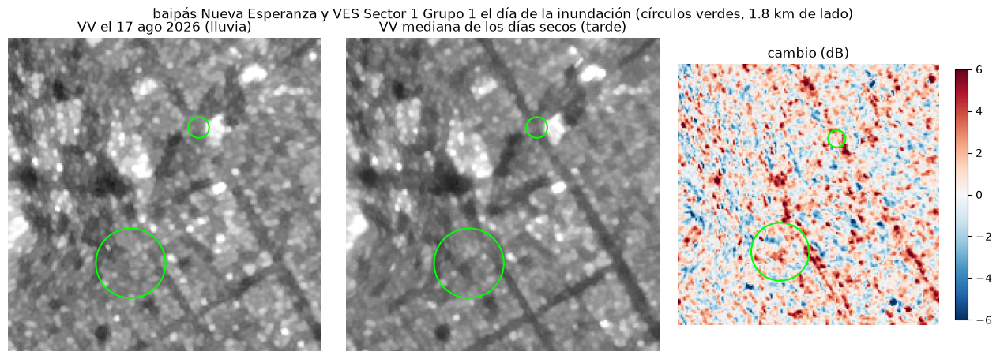

In [25]:
x, y = transform("EPSG:4326", ref["crs"], [-76.9453], [-12.1839])
f, c = rowcol(ref["transform"], x[0], y[0])
v = np.s_[f - 90:f + 90, c - 90:c + 90]
seco = base["lima_2026-08-17"][v]
fig, ejes = plt.subplots(1, 3, figsize=(13, 4.6))
ejes[0].imshow(vv_al["lima_2026-08-17"][v], cmap="gray", vmin=-20, vmax=5)
ejes[0].set_title("VV el 17 ago 2026 (lluvia)")
ejes[1].imshow(seco, cmap="gray", vmin=-20, vmax=5)
ejes[1].set_title("VV mediana de los días secos (tarde)")
im = ejes[2].imshow(vv_al["lima_2026-08-17"][v] - seco, cmap="RdBu_r", vmin=-6, vmax=6)
ejes[2].set_title("cambio (dB)")
plt.colorbar(im, ax=ejes[2], shrink=0.8)
for n in noticias[(noticias.escena == "lima_2026-08-17") & noticias.lugar.str.contains("baipás|Sector 1")].itertuples():
    xx, yy = transform("EPSG:4326", ref["crs"], [n.lon], [n.lat])
    ff, cc = rowcol(ref["transform"], xx[0], yy[0])
    for ax in ejes:
        ax.add_patch(plt.Circle((cc - c + 90, ff - f + 90), n.radio_m / 10, fill=False, color="lime", lw=1.5))
for ax in ejes:
    ax.axis("off")
plt.suptitle("baipás Nueva Esperanza y VES Sector 1 Grupo 1 el día de la inundación (círculos verdes, 1.8 km de lado)")
plt.tight_layout()

El caso de control de 2017 en el mapa: el Rímac cruza de derecha a izquierda; el Huaycoloro baja desde arriba y entra al
Rímac por Campoy.

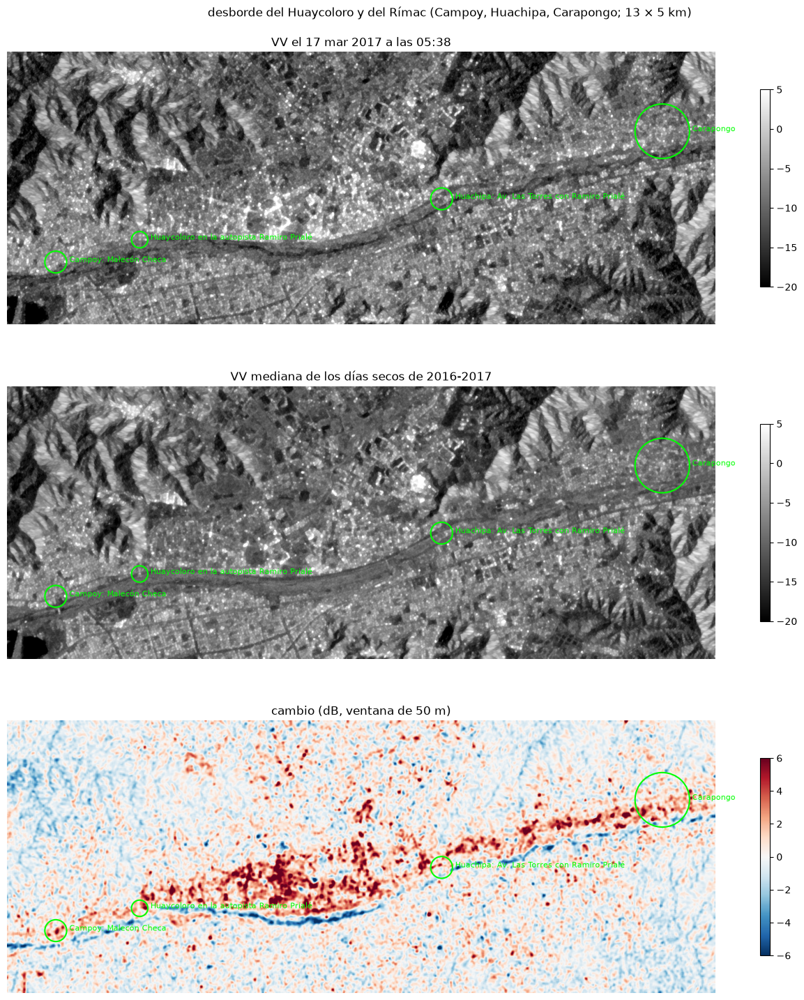

In [26]:
x, y = transform("EPSG:4326", ref["crs"], [-76.915], [-12.012])
f, c = rowcol(ref["transform"], x[0], y[0])
v = np.s_[f - 250:f + 250, c - 650:c + 650]
dia, seco = vv_al["lima_2017-03-17"][v], base["lima_2017-03-17"][v]
paneles = [(dia, "VV el 17 mar 2017 a las 05:38", "gray", -20, 5), (seco, "VV mediana de los días secos de 2016-2017", "gray", -20, 5),
           (ndimage.uniform_filter(np.nan_to_num(dia - seco), 5), "cambio (dB, ventana de 50 m)", "RdBu_r", -6, 6)]
fig, ejes = plt.subplots(3, 1, figsize=(13, 15))
for ax, (img, titulo, cm, v0, v1) in zip(ejes, paneles):
    im = ax.imshow(img, cmap=cm, vmin=v0, vmax=v1)
    for n in noticias[noticias.escena == "lima_2017-03-17"].itertuples():
        xx, yy = transform("EPSG:4326", ref["crs"], [n.lon], [n.lat])
        ff, cc = rowcol(ref["transform"], xx[0], yy[0])
        ax.add_patch(plt.Circle((cc - c + 650, ff - f + 250), n.radio_m / 10, fill=False, color="lime", lw=1.5))
        ax.text(cc - c + 655 + n.radio_m / 10, ff - f + 250, n.lugar.split(" (")[0], color="lime", fontsize=8)
    ax.set_title(titulo)
    ax.axis("off")
    plt.colorbar(im, ax=ax, shrink=0.6)
plt.suptitle("desborde del Huaycoloro y del Rímac (Campoy, Huachipa, Carapongo; 13 × 5 km)")
plt.tight_layout()

### 6.4 ¿El agua se queda? Agua empozada entre pasadas

Lo que interesa no es solo la inundación del momento: con las lloviznas de Lima el agua se **queda empozada** horas o días
en baipases, pistas sin drenaje y calles con el desagüe colapsado, hasta que se seca o la sacan con cisternas (en VES
Sector 1 el agua llegó a 1.5 m y se sacaron 115 000 galones en agosto; una cisterna de Emape sacó el agua del baipás Nueva
Esperanza el 9 nov). Ese baipás (Av. 26 de Noviembre con Av. Pachacútec) está entre los 21 pasos a desnivel de Lima con
alta probabilidad de aniego según Cenepred (Andina, 8 nov). Por eso sirve una pasada de 1 a 3 días después de la lluvia,
y el agua empozada debería aparecer en **dos pasadas seguidas**. Se mide:

* cuánta agua de lluvia (6.2) de una pasada sigue (a 20 m o menos) en la siguiente: 8 nov 05:38 → 9 nov 18:33, entre los
  aniegos del 4-5 nov y el del 9 nov en la madrugada, frente a pares de días secos separados lo mismo;
* en cada lugar con noticias de 2026, el cambio de VV (ventana de 70 m, todos los píxeles) en todas las pasadas del año:
  ¿sube después de la lluvia y vuelve al nivel de los días secos?

In [27]:
de_lluvia = lambda c: (lluvia[c] if c in lluvia else agua_de_lluvia(c, refs(c))) & lejos
pares = [("lima_2026-11-08", "lima_2026-11-09", "lluvia: después del 4-5 nov"),
         ("lima_2026-11-03", "lima_2026-11-08", "antes y después del 4-5 nov"),
         ("lima_2026-04-17", "lima_2026-04-18", "seco"), ("lima_2026-04-29", "lima_2026-04-30", "seco"),
         ("lima_2026-07-12", "lima_2026-07-17", "seco")]
filas, sigue = [], {}
for a, b, tipo in pares:
    ma, mb = de_lluvia(a), de_lluvia(b)
    sigue[a] = ma & ndimage.binary_dilation(mb, iterations=2)
    filas.append({"pasada 1": a[5:], "pasada 2": b[5:], "tipo": tipo, "agua de lluvia en la 1 (m²)": int(ma.sum()) * 100,
                  "agua de lluvia en la 2 (m²)": int(mb.sum()) * 100, "sigue en la 2 (m²)": int(sigue[a].sum()) * 100})
pd.DataFrame(filas)

,pasada 1,pasada 2,tipo,agua de lluvia en la 1 (m²),agua de lluvia en la 2 (m²),sigue en la 2 (m²)
0,2026-11-08,2026-11-09,lluvia: después del 4-5 nov,229100,124000,21300
1,2026-11-03,2026-11-08,antes y después del 4-5 nov,117700,229100,17900
2,2026-04-17,2026-04-18,seco,46500,26400,0
3,2026-04-29,2026-04-30,seco,30600,131000,7500
4,2026-07-12,2026-07-17,seco,87700,246900,6800


In [28]:
from rasterio.transform import xy

grupos, _ = ndimage.label(ndimage.binary_dilation(sigue["lima_2026-11-08"], iterations=2))
manchas = []
for k, sl in enumerate(ndimage.find_objects(grupos), 1):
    fs, cs = np.nonzero((grupos[sl] == k) & sigue["lima_2026-11-08"][sl])
    x, y = xy(ref["transform"], fs.mean() + sl[0].start, cs.mean() + sl[1].start)
    lon, lat = transform(ref["crs"], "EPSG:4326", [x], [y])
    manchas.append({"lat": round(lat[0], 4), "lon": round(lon[0], 4), "area_m2": len(fs) * 100})
pd.DataFrame(manchas).sort_values("area_m2", ascending=False).head(8)

,lat,lon,area_m2
5,-12.2743,-76.9028,8800
2,-12.2060,-77.0205,5300
4,-12.2704,-76.9085,3300
1,-12.2037,-76.9562,2600
0,-11.8576,-77.0570,900
3,-12.2427,-76.9093,400


In [29]:
sitios = noticias[noticias.escena.str[5:9] == "2026"].drop_duplicates("lugar")
fechas26 = sorted([c for c in vv_al if c[5:9] == "2026" and pase_de[c] != "otra"], key=lambda c: c[5:])
base |= {c: np.nanmedian(np.stack([vv_al[r] for r in refs(c)]), 0) for c in fechas26 if c not in base}
xs, ys = transform("EPSG:4326", ref["crs"], [-77.00, -76.88], [-12.14, -12.25])
(f0, f1), (c0, c1) = rowcol(ref["transform"], xs, ys)
serie, zonas = [], {}
for c in fechas26:
    v = en_ventanas(vv_al[c] - base[c], ~np.isnan(base[c]), 7)
    zonas[c] = v[f0:f1:7, c0:c1:7]
    for n in sitios.itertuples():
        x, y = transform("EPSG:4326", ref["crs"], [n.lon], [n.lat])
        f, k = rowcol(ref["transform"], x[0], y[0])
        serie.append({"lugar": n.lugar, "fecha": c[5:], "pase": pase_de[c],
                      "dia": "seco" if c in set(secas.clave) else "lluvia", "cambio_dB": v[f, k]})
serie = pd.DataFrame(serie)
rango = serie[serie.dia == "seco"].groupby(["lugar", "pase"]).cambio_dB.agg(["min", "max"])
tabla = serie[serie.dia == "lluvia"].join(rango, on=["lugar", "pase"])
tabla["valor"] = [f"{v:+.2f}" + (" *" if v > m else "") for v, m in zip(tabla.cambio_dB, tabla["max"])]
tabla = tabla.pivot(index="lugar", columns=["fecha", "pase"], values="valor")
secas26 = [c for c in fechas26 if c in set(secas.clave)]
tope = {p: np.nanmax(np.stack([zonas[c] for c in secas26 if pase_de[c] == p]), 0) for p in ["mañana", "tarde"]}
tabla.loc["% de Lima Sur con *"] = [f"{np.mean((zonas['lima_' + f] > tope[p])[~np.isnan(zonas['lima_' + f] + tope[p])]) * 100:.0f} %"
                                    for f, p in tabla.columns]
print("* = sube más que en todos los días secos del mismo pase")
tabla

* = sube más que en todos los días secos del mismo pase


fecha,2026-01-11,2026-08-17,2026-10-03,2026-10-22,2026-11-03,2026-11-08,2026-11-09
pase,mañana,tarde,mañana,tarde,tarde,mañana,tarde
lugar,,,,,,,
Hospital de Emergencias VES,+0.14,+0.75 *,+0.68 *,-1.48,-0.80,+0.78 *,-1.26
SJM Av. Los Héroes,-0.13,-0.78,+0.37,+1.32,+0.65,+0.20,-0.30
VES Sector 1 Grupo 1,+0.64,+2.32 *,-0.18,+0.05,+0.50,+1.50 *,+0.79
VMT José Gálvez,+0.08,-0.82,-0.57,-0.71,-0.88,+0.55,-1.07
baipás Nueva Esperanza,+0.98 *,+1.09,+0.03,-0.38,+0.31,+1.34 *,+0.95
% de Lima Sur con *,13 %,40 %,22 %,20 %,21 %,28 %,32 %


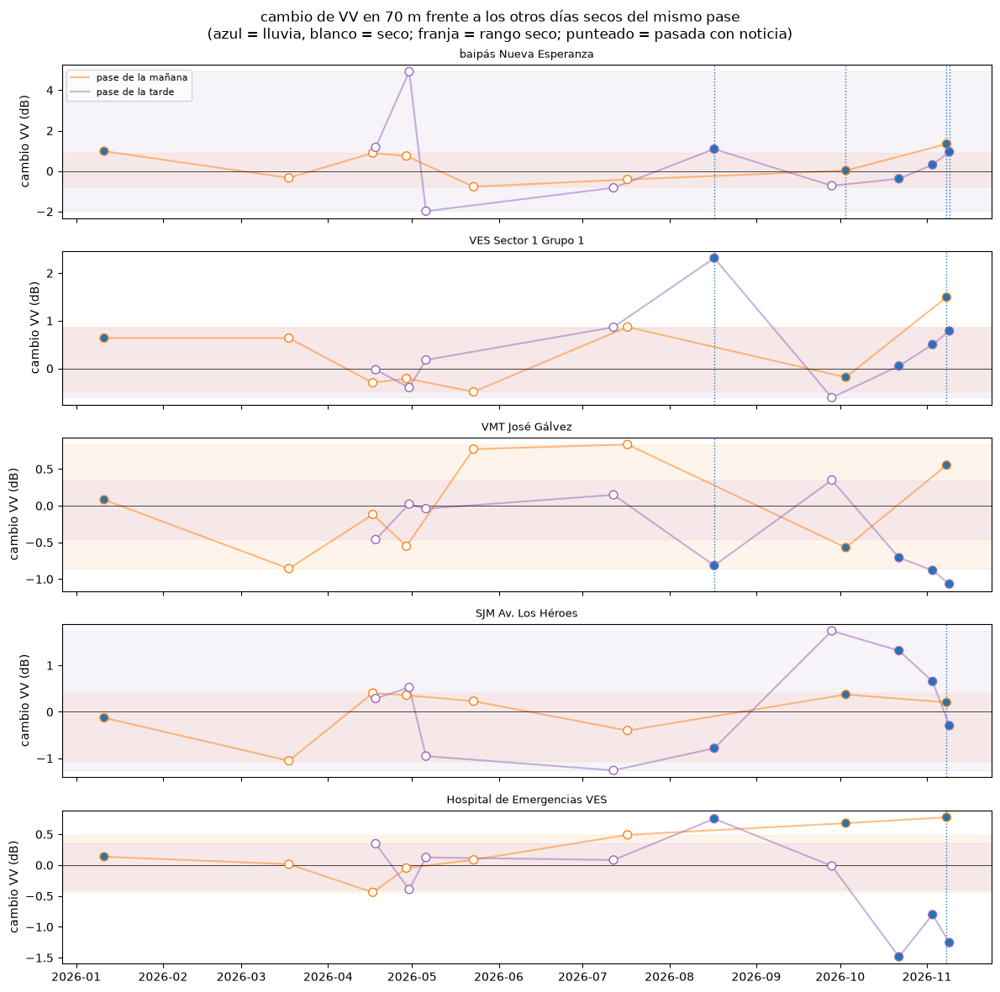

In [30]:
fig, ejes = plt.subplots(len(sitios), 1, figsize=(12, 2.4 * len(sitios)), sharex=True)
for ax, (lugar, g) in zip(ejes, serie.groupby("lugar", sort=False)):
    for p, color in [("mañana", "tab:orange"), ("tarde", "tab:purple")]:
        h = g[g.pase == p]
        fechas = pd.to_datetime(h.fecha)
        ax.plot(fechas, h.cambio_dB, "-", color=color, alpha=0.5, label=f"pase de la {p}")
        ax.scatter(fechas, h.cambio_dB, c=np.where(h.dia == "lluvia", "tab:blue", "white"), edgecolors=color, s=50, zorder=3)
        ax.axhspan(rango.loc[(lugar, p), "min"], rango.loc[(lugar, p), "max"], color=color, alpha=0.08)
    for e in noticias.escena[noticias.lugar == lugar]:
        ax.axvline(pd.Timestamp(e[5:]), color="tab:blue", ls=":", lw=1)
    ax.axhline(0, color="k", lw=0.5)
    ax.set_ylabel("cambio VV (dB)")
    ax.set_title(lugar, fontsize=9)
ejes[0].legend(fontsize=8)
plt.suptitle("cambio de VV en 70 m frente a los otros días secos del mismo pase\n(azul = lluvia, blanco = seco; franja = rango seco; punteado = pasada con noticia)")
plt.tight_layout()

**Resultado.**

* Del 8 al 9 nov siguen 21 300 m² de agua de lluvia, frente a 0-7500 m² en los pares de días secos; pero entre el 3 nov
  (antes de la lluvia) y el 8 nov también siguen 17 900 m², así que no todo es lluvia. Las manchas más grandes que siguen
  están en la orilla del mar de Lurín (8800 y 3300 m², olas y marea) y en dos terrenos de arena sin construir: Los Cedros
  en Chorrillos (5300 m²) y la Villa Panamericana en VES (2600 m²). Esos dos terrenos sí podrían ser agua empozada, pero no
  hay imagen óptica sin nubes de esos días para confirmarlo. En las calles con noticias no sigue nada.
* En los lugares con noticias, la pasada del 8 nov a las 05:38, tres días después de los aniegos del 4-5 nov, sube más que
  todos los días secos en 3 de los 4 lugares de ese aniego (baipás +1.34 dB, VES Sector 1 Grupo 1 +1.50 dB, Hospital de
  VES +0.78 dB). VES Sector 1 sube también el 17 ago a las 18:33 (+2.32 dB), cuando el agua estaba empozada hasta 1.5 m.
  Es lo esperado del agua entre paredes (doble rebote). Pero la llovizna moja toda Lima Sur: el 8 nov el 28 % de sus
  zonas de 70 m también sube más que todos los días secos (el 17 ago, el 40 %), y con 28 % que 3 de 4 lugares salgan así
  por azar pasa en un 7 % de los casos. El Hospital de VES sube igual en días sin noticia (17 ago, 3 oct), y el 9 nov a
  las 18:33, con el baipás inundado otra vez esa madrugada, ningún lugar sale del rango seco.
* El agua empozada en calles da una señal que va en el sentido esperado (sube, en los lugares reportados, días después),
  pero no se separa de la ciudad mojada. Con Sentinel-1 se puede, a lo más, marcar candidatos (terrenos abiertos que
  siguen oscuros dos pasadas) para revisarlos con otra imagen.

### 6.5 NISAR: radar de 5 m en banda L

NISAR (NASA-ISRO, en órbita desde 2025) entrega imágenes **RSLC**: números complejos (amplitud y fase) en geometría de
radar, con píxeles de 9.5 m × 4.5 m, cuatro veces más finos que Sentinel-1 GRD, y longitud de onda de 24 cm (banda L).
`descarga_datos.ipynb` (sección 5) baja dos pistas sobre Lima Sur; los días secos tienen a lo más 0.8 mm en cuatro días:

| Pista | Hora de Lima | Días secos | Días con lluvia o aniegos |
|---|---|---|---|
| 083 descendente | 18:25 | 3 y 27 nov 2025; 1, 13 y 25 jul, 30 ago, 17 oct 2026 | 14 ene, 18 ago y 5 oct 2026 |
| 003 ascendente | 05:58 | 29 oct 2025; 25 ago, 6 y 30 sep, 12 oct 2026 | 24 oct (llovizna del 22) y 5 nov 2026 |

Cada imagen se lleva a una grilla UTM de 5 m de Lima Sur. El archivo trae la posición en el mapa de una grilla de puntos
de la imagen a varias alturas; se interpola esa grilla a 0 y 500 m y se elige entre ambas con la altura del terreno (DEM
Copernicus de 30 m más 24 m de geoide). Se guardan la intensidad HH en dB y el valor complejo, que se usa en 6.6.

In [31]:
import re, gc, h5py
from scipy.interpolate import LinearNDInterpolator
from rasterio.transform import from_origin
from pyproj import Transformer

del vv_al, agua_al, alineados, probabilidad, base, lluvia
gc.collect()
sur =(-77.02, -12.28, -76.86, -12.10)
a_utm = Transformer.from_crs("EPSG:4326", "EPSG:32718", always_xy=True)
xs, ys = a_utm.transform([sur[0], sur[2], sur[0], sur[2]], [sur[1], sur[1], sur[3], sur[3]])
x0, x1, y0, y1 = 5 * np.floor(min(xs) / 5), 5 * np.ceil(max(xs) / 5), 5 * np.floor(min(ys) / 5), 5 * np.ceil(max(ys) / 5)
alto, ancho, T5 = int((y1 - y0) / 5), int((x1 - x0) / 5), from_origin(x0, y1, 5, 5)
perfil5 = dict(driver="GTiff", height=alto, width=ancho, count=1, dtype="float32", crs="EPSG:32718", transform=T5,
               compress="deflate", predictor=3, tiled=True, nodata=np.nan)
carpeta = Path("Data/procesado/nisar")
carpeta.mkdir(exist_ok=True)
if not (carpeta / "dem.tif").exists():
    margen = [sur[0] - 0.02, sur[1] - 0.02, sur[2] + 0.02, sur[3] + 0.02]
    items = requests.post("https://planetarycomputer.microsoft.com/api/stac/v1/search",
                          json={"collections": ["cop-dem-glo-30"], "bbox": margen}).json()["features"]
    token_dem = requests.get("https://planetarycomputer.microsoft.com/api/sas/v1/token/cop-dem-glo-30").json()["token"]
    arr, tr = merge([rasterio.open(i["assets"]["data"]["href"] + "?" + token_dem) for i in items], bounds=margen)
    dem = np.zeros((alto, ancho), "float32")
    reproject(arr[0].astype("float32"), dem, src_transform=tr, src_crs="EPSG:4326", dst_transform=T5, dst_crs="EPSG:32718",
              resampling=Resampling.bilinear)
    with rasterio.open(carpeta / "dem.tif", "w", **perfil5) as f:
        f.write(dem + 24.05, 1)
dem = rasterio.open(carpeta / "dem.tif").read(1)
cc, ff = np.meshgrid(np.arange(0, ancho, 10), np.arange(0, alto, 10))
lon, lat = Transformer.from_crs("EPSG:32718", "EPSG:4326", always_xy=True).transform(x0 + (cc + 0.5) * 5, y1 - (ff + 0.5) * 5)
fi, fj = np.mgrid[0:alto, 0:ancho].astype("float32") / 10


def a_grilla(h5):
    with h5py.File(h5) as f:
        g, s = f["science/LSAR/RSLC/metadata/geolocationGrid"], f["science/LSAR/RSLC/swaths"]
        t, r = s["zeroDopplerTime"][()], s["frequencyA/slantRange"][()]
        ta, ra = np.meshgrid((g["zeroDopplerTime"][()] - t[0]) / (t[1] - t[0]), (g["slantRange"][()] - r[0]) / (r[1] - r[0]),
                             indexing="ij")
        capas = []
        for k in (1, 2):
            X, Y = g["coordinateX"][k], g["coordinateY"][k]
            m = (X > sur[0] - 0.15) & (X < sur[2] + 0.15) & (Y > sur[1] - 0.15) & (Y < sur[3] + 0.15)
            grueso = LinearNDInterpolator(np.c_[X[m], Y[m]], np.c_[ta[m], ra[m]])(lon, lat)
            capas.append([ndimage.map_coordinates(grueso[..., i], [fi, fj], order=1, mode="nearest") for i in (0, 1)])
        az = capas[0][0] + dem / 500 * (capas[1][0] - capas[0][0])
        rg = capas[0][1] + dem / 500 * (capas[1][1] - capas[0][1])
        a0, r0 = max(0, int(np.nanmin(az)) - 3), max(0, int(np.nanmin(rg)) - 3)
        slc = s["frequencyA/HH"][a0:int(np.nanmax(az)) + 4, r0:int(np.nanmax(rg)) + 4].astype("complex64")
    slc[slc == 0] = np.nan
    muestrear = lambda x: ndimage.map_coordinates(x, [az - a0, rg - r0], order=1, cval=np.nan, prefilter=False)
    return 10 * np.log10(muestrear(np.abs(slc) ** 2)), (muestrear(slc.real) + 1j * muestrear(slc.imag)).astype("complex64")


filas = []
for h5 in sorted(Path("Data/crudos_nisar/lima").glob("*.h5")):
    fecha = re.search(r"_(\d{8})T", h5.name).group(1)
    if not (carpeta / f"slc_{fecha}.npy").exists():
        hh, compleja = a_grilla(h5)
        with rasterio.open(carpeta / f"hh_{fecha}.tif", "w", **perfil5) as f:
            f.write(hh.astype("float32"), 1)
        np.save(carpeta / f"slc_{fecha}.npy", compleja)
    filas.append({"fecha": fecha, "pista": h5.name[21:30], "hora_lima": f"{int(h5.name[52:54]) - 5:02d}:{h5.name[54:56]}"})
secos_nisar = ["20251103", "20251127", "20260701", "20260713", "20260725", "20260830", "20261017",
               "20251029", "20260825", "20260906", "20260930", "20261012"]
nisar = pd.DataFrame(filas).drop_duplicates("fecha")
nisar["dia"] = np.where(nisar.fecha.isin(secos_nisar), "seco", "lluvia")
nisar.groupby(["pista", "hora_lima", "dia"]).fecha.apply(", ".join)

pista      hora_lima  dia   
003_A_171  05:58      lluvia                                             20261024
                      seco       20251029, 20260825, 20260906, 20260930, 20261012
083_D_095  18:25      lluvia                         20260114, 20260818, 20261005
                      seco      20251103, 20251127, 20260701, 20260713, 202607...
Name: fecha, dtype: object

Cada imagen se ajusta a la misma calibración que los días secos de su pista (se le resta la diferencia de la mediana de
toda la zona) y se compara con la mediana de esos días secos, igual que en 6.3 pero con ventanas de 5 m. Zona urbana =
HH mayor que −10 dB en los días secos.

In [32]:
hh = {f: rasterio.open(carpeta / f"hh_{f}.tif").read(1) for f in nisar.fecha}
for p, g in nisar.groupby("pista"):
    comun = np.logical_and.reduce([np.isfinite(hh[f]) for f in g.fecha])
    nivel = {f: np.median(hh[f][comun]) for f in g.fecha}
    medio = np.median([nivel[f] for f in g.fecha[g.dia == "seco"]])
    for f in g.fecha:
        hh[f] -= nivel[f] - medio
pista_de = dict(zip(nisar.fecha, nisar.pista))
refs_n = lambda f: nisar.fecha[(nisar.pista == pista_de[f]) & (nisar.dia == "seco") & (nisar.fecha != f)]

lugares_n = pd.DataFrame([
    ("baipás Nueva Esperanza", -12.1804, -76.9435, 60, "20260818", "bus varado en el baipás (Andina, 17 ago)"),
    ("VES Sector 1 Grupo 1", -12.1874, -76.9471, 200, "20260818", "aguas servidas en 11 manzanas (Infobae, 16-18 ago)"),
    ("VMT José Gálvez", -12.2244, -76.9029, 300, "20260818", "viviendas inundadas (Caretas, 17 ago)"),
    ("baipás Nueva Esperanza", -12.1804, -76.9435, 60, "20261005", "inundado la madrugada del 2 oct (La República)"),
    ("baipás Nueva Esperanza", -12.1804, -76.9435, 60, "20261105", "inundado y cerrado el 5 nov (El Búho)"),
    ("VES Sector 1 Grupo 1", -12.1874, -76.9471, 200, "20261105", "desagüe colapsado, 4-5 nov (Caretas)"),
    ("SJM Av. Los Héroes", -12.1575, -76.9635, 150, "20261105", "aniegos el 4 nov (Caretas)"),
    ("Hospital de Emergencias VES", -12.2321, -76.9348, 100, "20261105", "aniego en el exterior, 5 nov (Andina)"),
], columns=["lugar", "lat", "lon", "radio_m", "fecha", "noticia"])
lugares_n["fila"], lugares_n["col"] = [np.int32(v) for v in rowcol(T5, *a_utm.transform(lugares_n.lon, lugares_n.lat))]
noticias_n = lugares_n[lugares_n.fecha.isin(nisar.fecha)]
base_n = {f: np.nanmedian(np.stack([hh[r] for r in refs_n(f)]), 0) for f in set(noticias_n.fecha) | set(secos_nisar) & set(nisar.fecha)}

resultado_n = []
for n in noticias_n.itertuples():
    lado = 2 * int(n.radio_m / 5) + 1
    v = en_ventanas(hh[n.fecha] - base_n[n.fecha], base_n[n.fecha] > -10, lado)
    ciudad = v[::lado // 2 + 1, ::lado // 2 + 1]
    ciudad = ciudad[~np.isnan(ciudad)]
    secos = [en_ventanas(hh[r] - base_n[r], base_n[r] > -10, lado)[n.fila, n.col] for r in refs_n(n.fecha)]
    resultado_n.append({"lugar": n.lugar, "fecha": n.fecha, "noticia": n.noticia, "cambio_HH_dB": round(float(v[n.fila, n.col]), 2),
                        "dias_secos_dB": f"{min(secos):+.2f} a {max(secos):+.2f}",
                        "zonas_de_Lima_Sur_que_cambian_menos_%": round(float((ciudad < v[n.fila, n.col]).mean() * 100), 1)})
resultado_n = pd.DataFrame(resultado_n)
resultado_n.to_csv("Data/procesado/nisar/validacion_noticias_nisar.csv", index=False)
resultado_n

,lugar,fecha,noticia,cambio_HH_dB,dias_secos_dB,zonas_de_Lima_Sur_que_cambian_menos_%
0,baipás Nueva Esperanza,20260818,"bus varado en el baipás (Andina, 17 ago)",-1.23,-1.16 a +0.75,4.8
1,VES Sector 1 Grupo 1,20260818,"aguas servidas en 11 manzanas (Infobae, 16-18 ...",-0.68,-0.64 a -0.02,32.7
2,VMT José Gálvez,20260818,"viviendas inundadas (Caretas, 17 ago)",-0.23,-0.49 a -0.21,87.5
3,baipás Nueva Esperanza,20261005,inundado la madrugada del 2 oct (La República),-0.57,-1.16 a +0.75,26.0


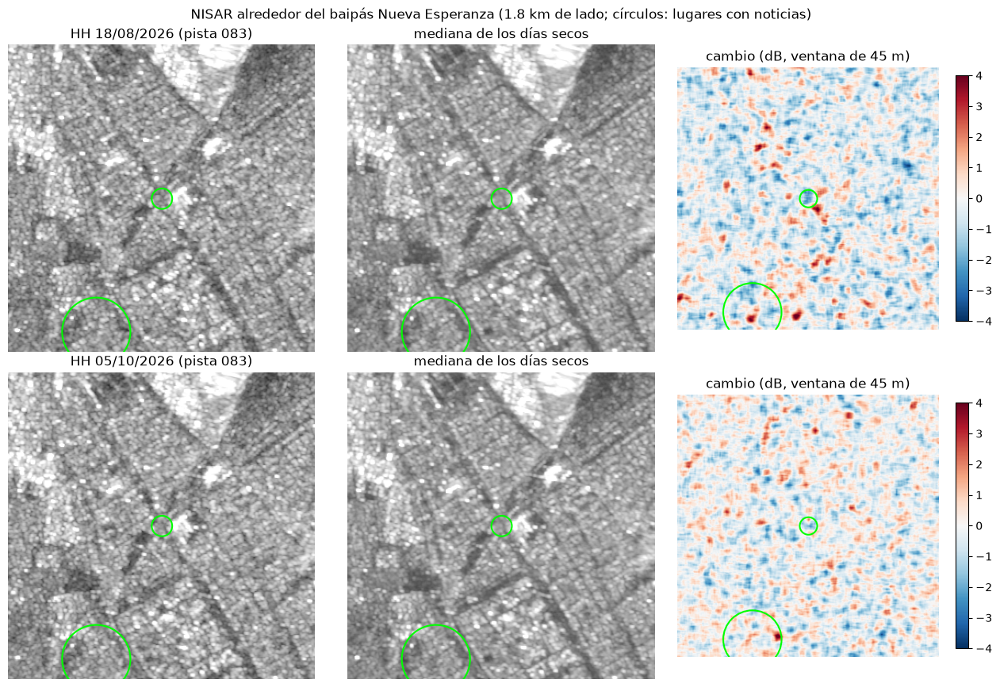

In [33]:
fechas = sorted(set(noticias_n.fecha[noticias_n.lugar == "baipás Nueva Esperanza"]))
baipas = lugares_n.iloc[0]
v = np.s_[baipas.fila - 180:baipas.fila + 180, baipas.col - 180:baipas.col + 180]
suave = lambda x: 10 * np.log10(ndimage.uniform_filter(np.nan_to_num(10 ** (x / 10)), 3) + 1e-6)
fig, ejes = plt.subplots(len(fechas), 3, figsize=(13, 4.4 * len(fechas)), squeeze=False)
for fila, f in zip(ejes, fechas):
    fila[0].imshow(suave(hh[f])[v], cmap="gray", vmin=-25, vmax=5)
    fila[0].set_title(f"HH {f[6:]}/{f[4:6]}/{f[:4]} (pista {pista_de[f][:3]})")
    fila[1].imshow(suave(base_n[f])[v], cmap="gray", vmin=-25, vmax=5)
    fila[1].set_title("mediana de los días secos")
    im = fila[2].imshow(ndimage.uniform_filter(np.nan_to_num(hh[f] - base_n[f]), 9)[v], cmap="RdBu_r", vmin=-4, vmax=4)
    fila[2].set_title("cambio (dB, ventana de 45 m)")
    plt.colorbar(im, ax=fila[2], shrink=0.8)
    for ax in fila:
        for n in lugares_n.drop_duplicates("lugar").itertuples():
            ax.add_patch(plt.Circle((n.col - baipas.col + 180, n.fila - baipas.fila + 180), n.radio_m / 5, fill=False, color="lime", lw=1.5))
        ax.axis("off")
plt.suptitle("NISAR alrededor del baipás Nueva Esperanza (1.8 km de lado; círculos: lugares con noticias)")
plt.tight_layout()

### 6.6 NISAR: ¿la lluvia rompe la coherencia?

Con dos imágenes complejas de la misma pista se mide la **coherencia** (0 a 1, ventana de 35 m): cuánto se mantiene la fase
de la señal en cada lugar entre dos fechas. Un charco o una calle mojada cambian la superficie y bajan la coherencia. Para
separar el efecto de una fecha *b* del simple paso del tiempo se usa el **índice de tríada** γ(a,c) − ½[γ(a,b) + γ(b,c)],
con *a* y *c* los pases secos más cercanos antes y después (12 días; para el 5 oct, *a* es el 30 ago, 36 días antes): es
positivo donde la fecha *b* rompe la coherencia. Se hace en la pista 083, la única con pases secos a ambos lados de las
fechas con noticias.

In [34]:
def coherencia(a, b, n=7):
    A, B = np.load(carpeta / f"slc_{a}.npy"), np.load(carpeta / f"slc_{b}.npy")
    cruz = np.nan_to_num(A * np.conj(B))
    num = ndimage.uniform_filter(cruz.real, n) + 1j * ndimage.uniform_filter(cruz.imag, n)
    den = np.sqrt(ndimage.uniform_filter(np.nan_to_num(np.abs(A) ** 2), n) * ndimage.uniform_filter(np.nan_to_num(np.abs(B) ** 2), n))
    return np.where(np.isnan(A) | np.isnan(B) | (den == 0), np.nan, np.abs(num) / np.maximum(den, 1e-12)).astype("float32")


trios = {"13 jul (seco)": ("20260701", "20260713", "20260725"),
         "18 ago (lluvia del 16-17)": ("20260725", "20260818", "20260830"),
         "5 oct (aniego del 2 oct)": ("20260830", "20261005", "20261017")}
urbano_n = base_n["20260725"] > -10
coh, indice, filas = {}, {}, []
for nombre, (fa, fb, fc) in trios.items():
    coh[nombre] = {"ab": coherencia(fa, fb), "bc": coherencia(fb, fc), "ac": coherencia(fa, fc)}
    indice[nombre] = coh[nombre]["ac"] - (coh[nombre]["ab"] + coh[nombre]["bc"]) / 2
    filas.append({"fecha b": nombre, **{f"γ({k[0]},{k[1]}) urbana": np.nanmedian(g[urbano_n]) for k, g in coh[nombre].items()},
                  "índice urbano": np.nanmedian(indice[nombre][urbano_n])})
pd.DataFrame(filas).round(3)

,fecha b,"γ(a,b) urbana","γ(b,c) urbana","γ(a,c) urbana",índice urbano
0,13 jul (seco),0.652,0.702,0.746,0.071
1,18 ago (lluvia del 16-17),0.401,0.458,0.692,0.241
2,5 oct (aniego del 2 oct),0.710,0.439,0.364,-0.191


In [35]:
filas = []
ventanas_i = {k: en_ventanas(i, urbano_n, 17) for k, i in indice.items()}
for n in lugares_n.drop_duplicates("lugar").itertuples():
    fila = {"lugar": n.lugar}
    for k, v in ventanas_i.items():
        ciudad = v[::9, ::9]
        fila[f"{k}: índice"] = round(float(v[n.fila, n.col]), 3)
        fila[f"{k}: % zonas con menos"] = round(float((ciudad[~np.isnan(ciudad)] < v[n.fila, n.col]).mean() * 100), 1)
    filas.append(fila)
coherencia_noticias = pd.DataFrame(filas)
coherencia_noticias.to_csv("Data/procesado/nisar/coherencia_noticias_nisar.csv", index=False)
coherencia_noticias

,lugar,13 jul (seco): índice,13 jul (seco): % zonas con menos,18 ago (lluvia del 16-17): índice,18 ago (lluvia del 16-17): % zonas con menos,5 oct (aniego del 2 oct): índice,5 oct (aniego del 2 oct): % zonas con menos
0,baipás Nueva Esperanza,-0.001,10.1,0.073,2.8,-0.082,96.7
1,VES Sector 1 Grupo 1,0.045,32.0,0.307,80.5,-0.209,36.9
2,VMT José Gálvez,0.051,36.2,0.423,97.6,-0.168,68.2
3,SJM Av. Los Héroes,0.041,29.3,0.222,41.4,-0.158,74.6
4,Hospital de Emergencias VES,0.087,66.8,0.400,96.3,-0.230,21.9


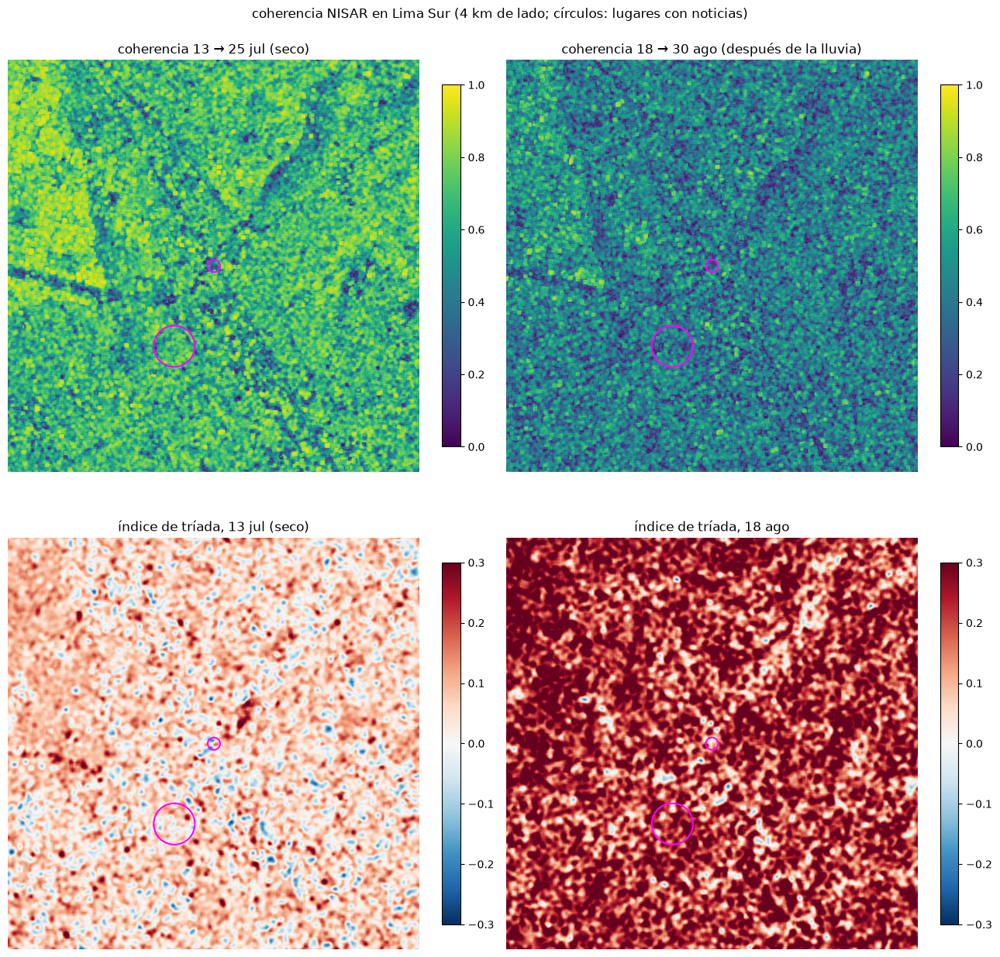

In [36]:
v = np.s_[baipas.fila - 400:baipas.fila + 400, baipas.col - 400:baipas.col + 400]
paneles = [(coh["13 jul (seco)"]["bc"], "coherencia 13 → 25 jul (seco)", "viridis", 0, 1),
           (coh["18 ago (lluvia del 16-17)"]["bc"], "coherencia 18 → 30 ago (después de la lluvia)", "viridis", 0, 1),
           (ndimage.uniform_filter(np.nan_to_num(indice["13 jul (seco)"]), 9), "índice de tríada, 13 jul (seco)", "RdBu_r", -0.3, 0.3),
           (ndimage.uniform_filter(np.nan_to_num(indice["18 ago (lluvia del 16-17)"]), 9), "índice de tríada, 18 ago", "RdBu_r", -0.3, 0.3)]
fig, ejes = plt.subplots(2, 2, figsize=(13, 13))
for ax, (img, titulo, cm, v0, v1) in zip(ejes.flat, paneles):
    im = ax.imshow(img[v], cmap=cm, vmin=v0, vmax=v1)
    for n in lugares_n.drop_duplicates("lugar").itertuples():
        ax.add_patch(plt.Circle((n.col - baipas.col + 400, n.fila - baipas.fila + 400), max(n.radio_m, 60) / 5, fill=False, color="magenta", lw=1.5))
    ax.set_title(titulo)
    ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.04)
plt.suptitle("coherencia NISAR en Lima Sur (4 km de lado; círculos: lugares con noticias)")
plt.tight_layout()

## 7. Conclusiones

* **Datos.** Las 14 escenas de Lima sirven para segmentar agua (sección 2.5); Dubái, El Cairo, Karachi y Mascate no, por la
  arena del desierto y el mar con viento. El modelo se entrena con 6 lluvias de Lima (1336 parches) y se valida con 2 (442).
* **Modelo.** Los tres encoders llegan a lo mismo: IoU de validación 0.982-0.984 (EfficientNet-B0 el mejor, época 19,
  umbral 0.65). Las pérdidas de train y validación bajan juntas: no hay sobreajuste visible.
* **Lima 2026 contra la máscara del mismo día.** IoU 0.92-0.98. Los peores son las pasadas de la tarde (17 ago, 22 oct:
  0.92-0.93), cuando el mar agitado por el viento no sale tan oscuro; los mejores, las de la mañana (3 oct, 8 nov:
  0.97-0.98). Cerca de un cuarto de cada escena es mar, fácil de acertar: el IoU alto mide sobre todo el mar.
* **El agua nueva no es de la lluvia (6.1-6.2).** Hay 1.8-10.3 km² de agua nueva por lluvia de 2026, pero el mismo cálculo
  en días secos da 2.1-9.4 km²: son las pistas del aeropuerto Jorge Chávez, la arena y la orilla del mar, que salen oscuras
  cualquier día. Al restar lo que ya es agua en los días secos de su pase y época quedan 0.15-0.63 km² en las lluvias de
  2026 y 0.04-0.62 km² en los propios días secos: no queda agua de lluvia por encima del ruido. Las lluvias de 2017-2019,
  que contra los días secos de 2026 dejaban unos 2 km², contra los de 2016-2017 dejan 0.40-0.82 km² (esos días secos:
  0.08-0.50): los 2 km² eran cambios de la costa entre años, no lluvia.
* **Caso de control: el desborde de 2017 sí se ve (6.3).** El 17 mar 2017 a las 05:38, con el Huaycoloro y el Rímac
  desbordados, VV sube 0.5-1.2 dB en los 4 lugares de la prensa (Huaycoloro en la Ramiro Prialé, Av. Las Torres en
  Huachipa, Malecón Checa en Campoy, Carapongo) y solo 1-3 de cada 100 zonas urbanas de Lima del mismo tamaño cambian igual
  o más; en 3 de los 4 el cambio queda fuera del rango de los días secos. En el mapa, Santa María de Huachipa y la orilla
  norte del Rímac hasta Carapongo suben 4-6 dB y el cauce sale más oscuro por la crecida. La U-Net no marca agua ahí (0 m²):
  el barro y el agua entre casas y chacras *suben* el radar. El cambio de VV contra días secos detecta una inundación de
  cuadras enteras; la U-Net, entrenada para agua oscura, no.
* **Los aniegos de 2026 no se detectan (6.3).** En los 9 casos (baipás Nueva Esperanza, VES Sector 1 Grupo 1, José Gálvez,
  Av. Los Héroes, Hospital de Emergencias de VES) la U-Net marca 0 m² de agua. VV sube entre 0.0 y 1.3 dB, como se espera
  del agua junto a paredes, pero ese día entre 2.5 y 27 de cada 100 zonas urbanas de Lima del mismo tamaño cambian igual o
  más, y en el baipás un día seco llegó a +2.1 dB. Solo el baipás el 8 nov sobresale (97.5 %), tres días después del aniego.
* **Agua empozada (6.4).** El agua que se queda horas o días debería verse en dos pasadas seguidas. Del 8 al 9 nov siguen
  0.021 km² de agua de lluvia (pares de días secos: 0-0.008 km²), pero del 3 al 8 nov, antes de la lluvia, también 0.018
  km². Lo que sigue está en la orilla del mar de Lurín y en dos terrenos de arena (Chorrillos y Villa Panamericana,
  2600-5300 m²), posibles charcos sin confirmar; nada en las calles con noticias. El 8 nov, tres días después de los
  aniegos, 3 de 4 lugares (baipás, VES Sector 1, Hospital de VES) suben más que todos los días secos (+0.8 a +1.5 dB), y
  VES Sector 1 también el 17 ago (+2.3 dB) con el agua empozada; pero la llovizna moja toda Lima Sur y ese día el 28 % de
  sus zonas sube igual (3 de 4 por azar: 7 %). La señal va en el sentido esperado, pero no se separa del ruido.
* **NISAR, con píxeles cuatro veces más finos, tampoco (6.5-6.6).** El 18 ago el baipás baja 1.2 dB, pero un día seco llegó
  a −1.2 dB; VES y José Gálvez quedan dentro de lo normal. La coherencia muestra que la lluvia del 16-17 ago cambió toda la
  ciudad (coherencia urbana 0.40-0.46 en los pares con el 18 ago frente a 0.69 entre el 25 jul y el 30 ago), no los
  lugares de las noticias: el baipás, con tráfico de buses, es de los que menos cambian (3 %) y el Hospital de VES, sin
  noticia ese día, de los que más (96 %). La pasada de NISAR del 5 nov a las 05:58, durante los aniegos, aún no está
  publicada.
* **Por qué.** (1) Sentinel-1 GRD separa unos 20 m y NISAR unos 5-10 m; el baipás mide unos 25 m de ancho y las calles
  10-15 m, entre paredes y puentes. (2) El agua entre casas *sube* el radar (doble rebote), y la etiqueta y la U-Net buscan
  agua oscura. (3) Muchas veces el agua empozada se saca con cisternas en horas (Emape en el baipás), así que la pasada
  siguiente encuentra poca; y la llovizna moja toda Lima Sur a la vez, así que el radar sube también donde no hay agua.
* **Qué haría falta.** Imágenes de ~1-3 m a la hora del aniego (radar ICEYE o Capella, PerúSAT-1, o Planet en días
  despejados) o reportes de campo con ubicación para etiquetar. Con Sentinel-1 y NISAR el proyecto sirve para agua abierta
  grande (mar, lagunas) y para desbordes de río que cubren cuadras enteras, como el de 2017; no para aniegos ni agua
  empozada en calles. A lo más marca candidatos en terrenos abiertos (6.4) para revisarlos con otra imagen.